---
# **BİL482 Doğal Dil İşleme — Uygulama Ödevi**
## **📰Türkçe Haber Metinleri Üzerinde Uçtan Uca Bir NLP Hattı:**
###**Türkçe Haber Metni Sınıflandırma**
---
| Alan | Bilgi |
|---|---|
| **Ad–Soyad** | Ceren Naz DERVİŞOĞLU |
| **Veri seti** | TTC4900 — *A Benchmark Data for Turkish Text Categorization* (`savasy/ttc4900`) |
| **Bağlantı** | https://huggingface.co/datasets/savasy/ttc4900 (kaynak: https://raw.githubusercontent.com/savasy/TurkishTextClassification/master/7allV03.csv) |
| **Lisans** | CC0: Public Domain |
| **Çalışma ortamı** | Google Colab, varsayılan CPU çalışma zamanı |

**Problem tanımı:** Bir Türkçe haber metnini yedi konu kategorisinden birine atayan çok sınıflı bir metin sınıflandırma görevidir. TTC4900 veri seti üzerinde ham metinden başlayarak ön işleme, dilbilgisel çözümleme, BoW/TF-IDF/Word2Vec ve BERTurk temsilleri oluşturulmakta ve sınıflandırıcıların başarısı macro-F1 ölçütüyle karşılaştırılmaktadır.

In [1]:
# ------------------------------------------------------------------
# KURULUM | Bu hücrede defterin ihtiyaç duyduğu tüm paketler kurulur,
# NLTK veri paketleri ve Stanza'nın Türkçe modelleri indirilir.
# Colab'da hazır gelen paketler (pandas, sklearn, torch, seaborn...)
# yeniden kurulmaz; yalnızca eksik olanlar eklenir.
# ------------------------------------------------------------------
!pip install -q stanza gensim wordcloud snowballstemmer transformers datasets

import nltk
# Türkçe stop-word listesi ve cümle bölücü (punkt) modelleri indirilir
for paket in ["stopwords", "punkt", "punkt_tab"]:
    nltk.download(paket, quiet=True)

import stanza
# Türkçe varsayılan hat (IMST: tokenize, mwt, pos, lemma, depparse + Starlang NER) indirilir
stanza.download("tr", verbose=False)
print("Kurulum tamamlandı.")

models/default.zip: reconstructing file:   0%|          |  0.00B /  338MB            

models/default.zip: downloading bytes:           |  0.00B            

Kurulum tamamlandı.


In [2]:
# ------------------------------------------------------------------
# KÜTÜPHANELER VE TOHUM | Bu hücrede defter boyunca kullanılacak
# kütüphaneler içe aktarılır, rastlantısallık içeren tüm işlemler için
# tohum değeri 42 olarak sabitlenir ve grafik ayarları yapılır.
# ------------------------------------------------------------------
import os, re, random, time, zlib, warnings
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
import torch

warnings.filterwarnings("ignore")          # kütüphane uyarıları çıktıyı kalabalıklaştırmasın

SEED = 42                                  # yönergede istenen sabit tohum
random.seed(SEED)                          # Python'un random modülü
np.random.seed(SEED)                       # NumPy
torch.manual_seed(SEED)                    # PyTorch (G7)

BASLANGIC_ZAMANI = time.time()             # defterin toplam çalışma süresini ölçmek için

# Türkçe karakterleri (ç, ğ, ı, ö, ş, ü) destekleyen DejaVu Sans yazı tipi kullanılır
TURKCE_FONT = fm.findfont(fm.FontProperties(family="DejaVu Sans"))
plt.rcParams.update({"font.family": "DejaVu Sans", "figure.dpi": 100,
                     "axes.titlesize": 12, "axes.labelsize": 10})
pd.set_option("display.max_colwidth", 120)
print("Yazı tipi:", TURKCE_FONT)

Yazı tipi: /usr/local/lib/python3.13/dist-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf


---
## **G1 · Veri Yükleme ve Keşifsel Analiz**
---
Bu bölümde TTC4900 veri seti kod içinden yüklenmekte ve yapısı incelenmektedir. Yükleme için önce Hugging Face üzerindeki `savasy/ttc4900` kimliği denenmekte, erişim sorunu yaşanması durumunda aynı verinin özgün GitHub bağlantısı kullanılmaktadır. Yüklenen verinin boyutu, sütunları ve ilk kayıtları gösterilmekte; eksik, boş ve tekrarlanan metinler tespit edilerek veriden çıkarılmaktadır. Ardından sınıf dağılımı ve metin uzunlukları tablo ve grafiklerle ortaya konmaktadır.

In [3]:
# ------------------------------------------------------------------
# G1-a | Bu hücrede veri seti kod içinden yüklenir.
# 1. yol: Hugging Face veri kimliği; 2. yol (yedek): özgün raw CSV bağlantısı.
# Sütun adları Türkçeleştirilir: metin (haber metni) ve kategori (etiket).
# ------------------------------------------------------------------
HF_VERI_KIMLIGI = "savasy/ttc4900"
YEDEK_URL = "https://raw.githubusercontent.com/savasy/TurkishTextClassification/master/7allV03.csv"

def veriyi_yukle():
    # Önce Hugging Face denenir; etiketler ClassLabel (tamsayı) ise adlarına çevrilir
    try:
        from datasets import load_dataset
        ds = load_dataset(HF_VERI_KIMLIGI, split="train")
        veri = ds.to_pandas()
        if pd.api.types.is_integer_dtype(veri["category"]):
            adlar = ds.features["category"].names
            veri["category"] = veri["category"].map(lambda i: adlar[i])
        kaynak = f"Hugging Face ({HF_VERI_KIMLIGI})"
    except Exception as hata:
        # Yedek yol: aynı verinin herkese açık raw CSV dosyası
        print("Hugging Face yüklemesi başarısız, yedek bağlantı kullanılıyor:", type(hata).__name__)
        veri = pd.read_csv(YEDEK_URL)
        kaynak = "raw GitHub CSV"
    veri = veri.rename(columns={"text": "metin", "category": "kategori"})
    veri["kategori"] = veri["kategori"].astype(str).str.strip()
    return veri[["metin", "kategori"]], kaynak

df, VERI_KAYNAGI = veriyi_yukle()
print("Veri kaynağı:", VERI_KAYNAGI)
print("Ham veri boyutu:", df.shape)

README.md:   0%|          | 0.00/6.70k [00:00<?, ?B/s]

ttc4900/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 5.51MB            

ttc4900/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/4900 [00:00<?, ? examples/s]

Veri kaynağı: Hugging Face (savasy/ttc4900)
Ham veri boyutu: (4900, 2)


In [4]:
# ------------------------------------------------------------------
# G1-b | Bu hücrede veri boyutu, sütunlar, ilk 5 kayıt ve eksik değerler
# gösterilir; ardından eksik, boş ve tekrarlanan metinler temizlenir.
# ------------------------------------------------------------------
print("Boyut (satır, sütun):", df.shape)
print("Sütunlar:", list(df.columns))
print("\nVeri tipleri:\n", df.dtypes, sep="")
display(df.head())

# Eksik (NaN) ve boş/yalnızca boşluktan oluşan metinlerin sayısı
eksik = df.isna().sum()
bos_metin = (df["metin"].fillna("").str.strip() == "").sum()
tekrar = df.duplicated(subset="metin").sum()
print("Eksik değer sayısı:\n", eksik, sep="")
print("Boş metin sayısı:", bos_metin)
print("Tekrarlanan (aynı metne sahip) kayıt sayısı:", tekrar)

# Temizlik: NaN ve boş metinler atılır; aynı metin birden fazla kez geçiyorsa ilki tutulur.
# Tekrarların atılması, aynı haberin hem eğitim hem test kümesine düşmesini (veri sızıntısı) önler.
df = df.dropna(subset=["metin", "kategori"])
df = df[df["metin"].str.strip() != ""]
df = df.drop_duplicates(subset="metin", keep="first").reset_index(drop=True)
print("\nTemizlik sonrası boyut:", df.shape)

Boyut (satır, sütun): (4900, 2)
Sütunlar: ['metin', 'kategori']

Veri tipleri:
metin       object
kategori    object
dtype: object


,metin,kategori
0,3 milyon ile ön seçim vaadi mhp nin 10 olağan büyük kurultayı nda konuşan genel başkan adayı koray_aydın seçimlerde...,siyaset
1,mesut_yılmaz yüce_divan da ceza alabilirdi prof dr sacit adalı isviçre deki banka eski başbakan mesut_yılmaz ın ban...,siyaset
2,disko lar kaldırılıyor başbakan_yardımcısı arınç disko diye tabir edilen disiplin koğuşlarının kaldırılacağını söyl...,siyaset
3,sarıgül anayasa_mahkemesi ne gidiyor mustafa_sarıgül ilçedeki sınır değişikliğine itiraz için anayasa_mahkemesi ne ...,siyaset
4,erdoğan idamın bir haklılık sebebi var demek ki yeri geldiği zaman idamın bir haklılık sebebi de var kendimizi chec...,siyaset


Eksik değer sayısı:
metin       0
kategori    0
dtype: int64
Boş metin sayısı: 0
Tekrarlanan (aynı metne sahip) kayıt sayısı: 361

Temizlik sonrası boyut: (4539, 2)


In [5]:
# ------------------------------------------------------------------
# G1-a | Temizlikten sonra örneklem kontrolü. Yönergeye göre veri çok büyükse (5.000'den fazla
# kayıt) sınıf oranları korunarak 2.000–5.000 kayıtlık örneklem alınmalıdır.
# ------------------------------------------------------------------
from sklearn.model_selection import train_test_split

UST_SINIR = 5000          # bu sayının üzerindeki veri setleri örneklenir
ORNEKLEM_BOYUTU = 3000    # örneklem gerekirse alınacak kayıt sayısı

if len(df) > UST_SINIR:
    df, _ = train_test_split(df, train_size=ORNEKLEM_BOYUTU,
                             stratify=df["kategori"], random_state=SEED)
    df = df.reset_index(drop=True)
    print(f"Sınıf oranları korunarak {ORNEKLEM_BOYUTU} kayıtlık örneklem alındı.")
else:
    print(f"Veri {len(df)} kayıt (>= 1.000 ve <= {UST_SINIR}); örnekleme gerekmedi, tamamı kullanılıyor.")

Veri 4539 kayıt (>= 1.000 ve <= 5000); örnekleme gerekmedi, tamamı kullanılıyor.


,Kayıt sayısı,Oran (%)
kategori,,
siyaset,690,15.20
ekonomi,690,15.20
dunya,677,14.92
teknoloji,647,14.25
spor,636,14.01
saglik,632,13.92
kultur,567,12.49


En büyük / en küçük sınıf oranı: 1.22
Yorum: Belirgin bir dengesizlik yok (oran < 1.5).


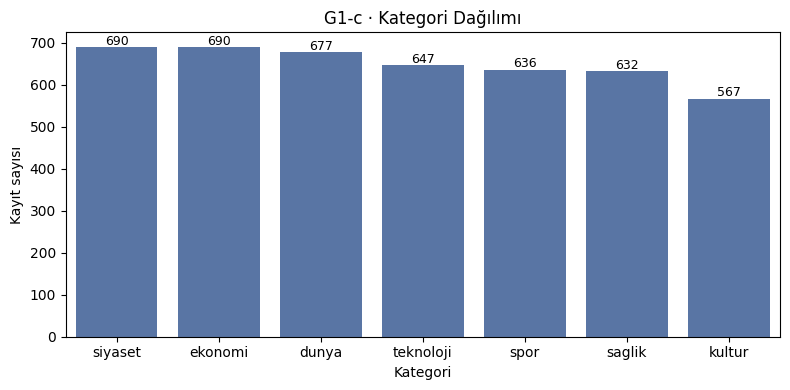

In [6]:
# ------------------------------------------------------------------
# G1-c | Bu hücrede sınıf dağılımı tablo ve çubuk grafikle verilir;
# en büyük/en küçük sınıf oranı ile dengesizlik ölçülür.
# ------------------------------------------------------------------
sinif_sayilari = df["kategori"].value_counts()
sinif_tablosu = pd.DataFrame({"Kayıt sayısı": sinif_sayilari,
                              "Oran (%)": (100 * sinif_sayilari / len(df)).round(2)})
display(sinif_tablosu)

dengesizlik_orani = sinif_sayilari.max() / sinif_sayilari.min()
print(f"En büyük / en küçük sınıf oranı: {dengesizlik_orani:.2f}")
print("Yorum:", "Belirgin bir dengesizlik yok (oran < 1.5)." if dengesizlik_orani < 1.5
      else "Sınıflar arasında dengesizlik var; macro metrikler esas alınmalı.")

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=sinif_sayilari.index, y=sinif_sayilari.values, ax=ax, color="#4C72B0")
for i, deger in enumerate(sinif_sayilari.values):          # çubukların üzerine sayılar yazılır
    ax.text(i, deger + 5, str(deger), ha="center", fontsize=9)
ax.set_title("G1-c · Kategori Dağılımı")
ax.set_xlabel("Kategori"); ax.set_ylabel("Kayıt sayısı")
plt.tight_layout(); plt.show()

,Ortalama,Medyan,En kısa,En uzun
kategori,,,,
siyaset,338.1,264.0,8,1511
saglik,329.8,303.5,41,1069
ekonomi,329.1,270.5,16,1771
kultur,262.7,204.0,14,2711
teknoloji,223.0,166.0,8,1221
spor,204.1,166.5,22,2642
dunya,194.3,144.0,25,2033


Genel ortalama kelime sayısı: 269.5


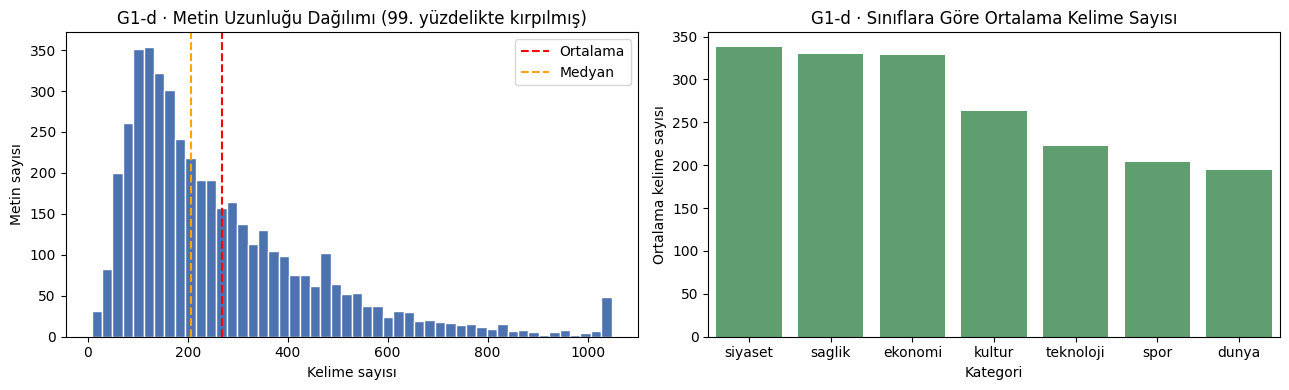

In [7]:
# ------------------------------------------------------------------
# G1-d | Bu hücrede her metnin kelime sayısı hesaplanır; dağılım histogram
# ile çizilir ve sınıflara göre ortalama uzunluk raporlanır.
# ------------------------------------------------------------------
df["kelime_sayisi"] = df["metin"].str.split().str.len()   # boşluğa göre kaba kelime sayımı

uzunluk_tablosu = (df.groupby("kategori")["kelime_sayisi"]
                     .agg(["mean", "median", "min", "max"]).round(1)
                     .rename(columns={"mean": "Ortalama", "median": "Medyan",
                                      "min": "En kısa", "max": "En uzun"})
                     .sort_values("Ortalama", ascending=False))
display(uzunluk_tablosu)
print("Genel ortalama kelime sayısı:", round(df["kelime_sayisi"].mean(), 1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
# Sol: tüm verinin histogramı (uzun kuyruk nedeniyle 99. yüzdelik ile kırpılmış eksen)
ust = df["kelime_sayisi"].quantile(0.99)
axes[0].hist(df["kelime_sayisi"].clip(upper=ust), bins=50, color="#4C72B0", edgecolor="white")
axes[0].axvline(df["kelime_sayisi"].mean(), color="red", ls="--", label="Ortalama")
axes[0].axvline(df["kelime_sayisi"].median(), color="orange", ls="--", label="Medyan")
axes[0].set_title("G1-d · Metin Uzunluğu Dağılımı (99. yüzdelikte kırpılmış)")
axes[0].set_xlabel("Kelime sayısı"); axes[0].set_ylabel("Metin sayısı"); axes[0].legend()
# Sağ: sınıflara göre ortalama uzunluk
sns.barplot(x=uzunluk_tablosu.index, y=uzunluk_tablosu["Ortalama"], ax=axes[1], color="#55A868")
axes[1].set_title("G1-d · Sınıflara Göre Ortalama Kelime Sayısı")
axes[1].set_xlabel("Kategori"); axes[1].set_ylabel("Ortalama kelime sayısı")
plt.tight_layout(); plt.show()

## G1 · Değerlendirme
- Veri Hugging Face üzerinden (`savasy/ttc4900`) yüklenmiş; 4.900 kayıt ve iki sütundan (metin, kategori) oluştuğu görülmüştür. Eksik veya boş metin bulunmamakla birlikte **361 tekrarlanan haber** tespit edilmiştir. Bu kayıtlar, aynı haberin hem eğitim hem test kümesine düşmesini (veri sızıntısı) önlemek amacıyla veriden çıkarılmış ve **4.539 kayıt** ile devam edilmiştir.
- Veri 5.000 kaydın altında kaldığından örnekleme yapılmamış, verinin tamamı kullanılmıştır. Örneklem kararı, analizde gerçekten kullanılacak kayıt sayısını yansıtması için temizlik sonrasında verilmiştir.
- Özgün veride her sınıf 700 kayıtla tam dengelidir. Tekrarların atılmasından sonra sınıf büyüklükleri 567 (kültür) ile 690 (siyaset, ekonomi) arasında değişmektedir. En büyük/en küçük sınıf oranı **1,22** olduğundan ciddi bir dengesizlik bulunmamaktadır; yine de kültür sınıfı görece küçük kaldığı için G6'da macro metrikler esas alınmıştır.
- Metinler ortalama **269,5 kelime** uzunluğundadır ve dağılım sağa çarpıktır: tüm sınıflarda medyan ortalamanın altında kalmakta, 2.700 kelimeyi aşan haberler bulunmaktadır. Siyaset, sağlık ve ekonomi haberleri ortalama 329–338 kelimeyle en uzun, dünya ve spor haberleri ise 194–204 kelimeyle en kısa sınıflardır. Uzunluk farkının ham frekansa dayanan temsillerde uzun metinleri baskın kılabileceği göz önüne alınarak G6'da TF-IDF için `sublinear_tf` ve L2 normalizasyonu kullanılmıştır.

---
## **G2 · Metin Ön İşleme**
---

Bu bölümde ham haber metinleri, analiz ve modelleme adımlarında kullanılabilecek temiz bir biçime getirilmektedir. Türkçeye uygun küçük harf dönüşümü, gereksiz karakterlerin temizlenmesi, tokenization, stop-word temizliği ve gövdeleme adımları sırasıyla uygulanmaktadır. Bölümün sonunda tüm adımlar tek bir `on_isle()` fonksiyonunda birleştirilerek veri setinin tamamına uygulanmaktadır.

In [8]:
# ------------------------------------------------------------------
# G2-a | Bu hücrede Türkçeye uygun küçük harfe çevirme fonksiyonu yazılır.
# Python'un str.lower() fonksiyonu 'I' harfini 'i'ye, 'İ' harfini ise
# 'i' + birleşik nokta (U+0307) dizisine çevirir; Türkçede doğrusu I→ı, İ→i'dir.
# ------------------------------------------------------------------
def turkce_kucuk_harf(metin: str) -> str:
    # Önce Türkçeye özgü iki büyük harf elle dönüştürülür, sonra standart lower() uygulanır
    return metin.replace("I", "ı").replace("İ", "i").lower()

ornek = "IŞIK İSTANBUL'DA, ILGAZ'DA VE IĞDIR'DA İNCELEME YAPTI."
standart = ornek.lower()
turkce = turkce_kucuk_harf(ornek)

karsilastirma = pd.DataFrame({
    "Yöntem": ["Özgün metin", "str.lower()", "turkce_kucuk_harf()"],
    "Sonuç": [ornek, standart, turkce],
    "Uzunluk": [len(ornek), len(standart), len(turkce)]})
display(karsilastirma)
# str.lower() sonucunda 'İ' iki karaktere (i + U+0307) dönüştüğü için metin uzar
print("str.lower() 'İ' için ürettiği karakterler:", [hex(ord(c)) for c in "İ".lower()])
print("'ışık' kelimesi standart lower ile doğru mu?", "ışık" in standart, "| Türkçe fonksiyonla:", "ışık" in turkce)

,Yöntem,Sonuç,Uzunluk
0,Özgün metin,"IŞIK İSTANBUL'DA, ILGAZ'DA VE IĞDIR'DA İNCELEME YAPTI.",54
1,str.lower(),"işik i̇stanbul'da, ilgaz'da ve iğdir'da i̇nceleme yapti.",56
2,turkce_kucuk_harf(),"ışık istanbul'da, ılgaz'da ve ığdır'da inceleme yaptı.",54


str.lower() 'İ' için ürettiği karakterler: ['0x69', '0x307']
'ışık' kelimesi standart lower ile doğru mu? False | Türkçe fonksiyonla: True


In [9]:
# ------------------------------------------------------------------
# G2-b | Bu hücrede URL, e-posta, sayı, noktalama ve özel karakter temizliği
# Türkçe harfler korunarak yapılır.
# ------------------------------------------------------------------
URL_DESENI = re.compile(r"(https?://\S+|www\.\S+|\bcom tr\b|\b(?:http|https|www|com|net|org|html?)\b)")  # veri setinde noktaları silinmiş alan adı kalıntıları da (hurriyet com tr) temizlenir
EPOSTA_DESENI = re.compile(r"\b[\w.+-]+@[\w-]+\.[\w.-]+\b")
SAYI_DESENI = re.compile(r"\d+")
# Türkçe alfabe dışındaki her şey (noktalama, simgeler, Windows-1252 kalıntıları) silinir.
# Alt çizgi korunur: veri setinde çok kelimeli özel adlar (koray_aydın) bu şekilde birleştirilmiştir.
TURKCE_DISI_DESEN = re.compile(r"[^a-zçğıöşü_\s]")
SAPKALI_HARFLER = str.maketrans({"â": "a", "î": "i", "û": "u", "Â": "a", "Î": "i", "Û": "u"})

def temizle(metin: str) -> str:
    metin = turkce_kucuk_harf(str(metin))
    metin = metin.translate(SAPKALI_HARFLER)        # kâğıt→kağıt, hâlâ→hala: aynı kelimenin iki yazımı birleşir
    metin = EPOSTA_DESENI.sub(" ", metin)           # e-posta adresleri (URL'den önce: ".com" parçası korunmalı)
    metin = URL_DESENI.sub(" ", metin)              # bağlantılar
    metin = SAYI_DESENI.sub(" ", metin)             # rakamlar (konu sınıflandırmada bilgi taşımaz)
    metin = TURKCE_DISI_DESEN.sub(" ", metin)       # noktalama ve özel karakterler
    metin = re.sub(r"_+", "_", metin).strip("_")    # art arda alt çizgiler sadeleştirilir
    return re.sub(r"\s+", " ", metin).strip()       # fazla boşluklar tek boşluğa indirilir

deneme = ("Detaylar için https://www.ornek.com.tr/haber?id=12 adresine bakın ya da bilgi@ornek.com'a "
          "yazın! 2012'de %15 büyüyen ŞİRKET, Kâğıt üretimini 3 KATINA çıkardı... #ekonomi \x93alıntı\x94")
print("Ham    :", deneme)
print("Temiz  :", temizle(deneme))
print()
print("Veriden örnek (ilk 300 karakter)")
print("Ham    :", df.loc[3, "metin"][:300])
print("Temiz  :", temizle(df.loc[3, "metin"])[:300])

Ham    : Detaylar için https://www.ornek.com.tr/haber?id=12 adresine bakın ya da bilgi@ornek.com'a yazın! 2012'de %15 büyüyen ŞİRKET, Kâğıt üretimini 3 KATINA çıkardı... #ekonomi alıntı
Temiz  : detaylar için adresine bakın ya da a yazın de büyüyen şirket kağıt üretimini katına çıkardı ekonomi alıntı

Veriden örnek (ilk 300 karakter)
Ham    :  sarıgül anayasa_mahkemesi ne gidiyor mustafa_sarıgül ilçedeki sınır değişikliğine itiraz için anayasa_mahkemesi ne başvuracak şişli_belediye_başkanı_mustafa_sarıgül büyükşehir_yasası ile birlikte ilçedeki sınır değişikliliğine itiraz için cuma günü anayasa_mahkemesi ne başvuruda bulunacak büyükşehi
Temiz  : sarıgül anayasa_mahkemesi ne gidiyor mustafa_sarıgül ilçedeki sınır değişikliğine itiraz için anayasa_mahkemesi ne başvuracak şişli_belediye_başkanı_mustafa_sarıgül büyükşehir_yasası ile birlikte ilçedeki sınır değişikliliğine itiraz için cuma günü anayasa_mahkemesi ne başvuruda bulunacak büyükşehir


In [10]:
# ------------------------------------------------------------------
# G2-c | Bu hücrede cümle ve kelime düzeyinde tokenization uygulanır.
# NLTK'nin Türkçe punkt modeli noktalamaya dayanarak cümle böler; veri setinde
# noktalama silinmiş olduğundan bu bölücü veri üzerinde tek bir "cümle" üretir.
# Bu nedenle G4 ve G7'de kullanmak üzere yüklem kalıplarına
# dayalı basit bir "sözde cümle" bölücü de tanımlanır.
# ------------------------------------------------------------------
from nltk.tokenize import sent_tokenize, word_tokenize

noktalamali = "Ali kitabı Ayşe'ye verdi. Ayşe çok sevindi! Peki, kitap hangi yıl basılmıştı?"
print("Noktalamalı örnek  -> cümleler:", sent_tokenize(noktalamali, language="turkish"))
print("Noktalamalı örnek  -> kelimeler:", word_tokenize(noktalamali, language="turkish"))

veri_ornegi = df.loc[0, "metin"]
print("\nVeri örneğinde punkt ile bulunan cümle sayısı:", len(sent_tokenize(veri_ornegi, language="turkish")))

# Haber dilinde cümleler çoğunlukla bu çekimli yüklemlerle biter
YUKLEM_KALIPLARI = {"dedi", "söyledi", "belirtti", "açıkladı", "vurguladı", "bildirdi", "kaydetti",
                    "etti", "bulundu", "oldu", "verdi", "aldı", "yaptı", "geldi", "başladı", "konuştu",
                    "kazandı", "gerçekleştirdi", "ediyor", "olacak", "gerekiyor", "bulunuyor"}

def sozde_cumle_bol(metin, en_az=5, en_cok=25):
    # Metin kelimelere ayrılır; bir yüklem kalıbı görülünce cümle kapatılır.
    # Çok kısa (< en_az) veya çok uzun (> en_cok) parçalar güvenilmez olduğundan atılır.
    cumleler, gecici = [], []
    for kelime in str(metin).split():
        gecici.append(kelime)
        if kelime in YUKLEM_KALIPLARI:
            if en_az <= len(gecici) <= en_cok:
                cumleler.append(" ".join(gecici))
            gecici = []
    return cumleler

def kelimelere_ayir(metin):
    # Kelime tokenization: NLTK word_tokenize (Türkçe), temizlenmiş metin üzerinde
    return word_tokenize(metin, language="turkish")

sozde = sozde_cumle_bol(veri_ornegi)
print("Sözde cümle bölücü ile bulunan cümle sayısı:", len(sozde))
for i, c in enumerate(sozde[:3], 1):
    print(f"  Cümle {i}: {c}")
print("\nİlk cümlenin kelime tokenları:", kelimelere_ayir(temizle(sozde[0])))

Noktalamalı örnek  -> cümleler: ["Ali kitabı Ayşe'ye verdi.", 'Ayşe çok sevindi!', 'Peki, kitap hangi yıl basılmıştı?']
Noktalamalı örnek  -> kelimeler: ['Ali', 'kitabı', "Ayşe'ye", 'verdi', '.', 'Ayşe', 'çok', 'sevindi', '!', 'Peki', ',', 'kitap', 'hangi', 'yıl', 'basılmıştı', '?']

Veri örneğinde punkt ile bulunan cümle sayısı: 1
Sözde cümle bölücü ile bulunan cümle sayısı: 4
  Cümle 1: ve taşkınlıklara izin verilmeyeceğini salonda sükunet sağlanmadan konuşmaların başlamayacağını vurguladı
  Cümle 2: türkeş devlet_bahçeli nin kurultay açılışında konuştuğu için adaylık nedeniyle ikinci bir konuşma yapmayacağını açıkladı
  Cümle 3: şubat ta 1 milyon olarak toplanirsak … kimsenin türkiye de olanlara arkasını dönemeyeceğini ifade eden aydın özetle şunları söyledi

İlk cümlenin kelime tokenları: ['ve', 'taşkınlıklara', 'izin', 'verilmeyeceğini', 'salonda', 'sükunet', 'sağlanmadan', 'konuşmaların', 'başlamayacağını', 'vurguladı']


In [11]:
# ------------------------------------------------------------------
# G2-d | Bu hücrede stop-word listesi oluşturulur: NLTK Türkçe listesi +
# veriye özgü eklemeler. Listeden bilerek çıkarılan kelimeler
# sınıf dağılımlarıyla gerekçelendirilir.
# ------------------------------------------------------------------
from nltk.corpus import stopwords
NLTK_STOP = set(stopwords.words("turkish"))
print("NLTK Türkçe stop-word sayısı:", len(NLTK_STOP))

# (1) Kesme işaretinin silinmesiyle kelimeden kopan ekler: "mhp nin", "ankara da", "ab ye"
KOPUK_EKLER = {"nin", "nın", "nun", "nün", "in", "ın", "un", "ün", "ye", "ya", "yi", "yı", "yu", "yü",
               "e", "a", "i", "ı", "u", "ü", "de", "da", "te", "ta", "den", "dan", "ten", "tan",
               "nde", "nda", "nden", "ndan", "ne", "na", "ni", "nı", "nu", "nü", "le", "la", "yle", "yla",
               "deki", "daki", "teki", "taki", "dir", "dır", "dur", "dür", "tir", "tır", "lar", "ler",
               "li", "lı", "lu", "lü"}   # "chp li", "pkk lı"
# (2) Haber dilinde her kategoride sık geçen, konu ayırt etmeyen işlev ve aktarma kelimeleri
HABER_DILI = {"bir", "olarak", "olan", "olduğunu", "olduğu", "kadar", "sonra", "önce", "göre", "ilgili",
              "tarafından", "ifade", "etti", "dedi", "söyledi", "belirtti", "kaydetti", "açıkladı",
              "var", "ancak", "arasında", "oldu", "eden", "yapılan", "şekilde", "bunun", "bunu", "buna",
              "diğer", "birlikte", "üzerine", "üzerinde", "karşı", "kendi", "ben", "sen", "onun", "olacak",
              "olması", "ayrıca", "ise", "ile", "değil", "yok", "dile", "getirdi", "belirten", "şöyle",
              "zaman", "içinde", "aynı", "sadece", "fazla", "iki", "ilk", "son", "yeni", "büyük", "iyi",
              "bulunan", "nedeniyle", "konusunda", "özellikle", "olduğunu", "yer", "aldı", "verdi", "eden",
              "devam", "ardından", "gelen", "alan", "sahip", "bin", "biri", "ben", "bizim", "siz", "onlar",
              "aa"}   # "aa": Anadolu Ajansı kısaltması, her kategoride kaynak bilgisi olarak geçer
# (3) Bilerek KORUNAN kelimeler: çok sık geçseler de belirli kategorilere yığıldıkları için
#     konu sınıflandırmasında ayırt edicidirler (dağılım aşağıda gösterilmiştir).
KORUNANLAR = {"yüzde", "milyon", "milyar", "dolar", "dr"}

STOP_WORDS = (NLTK_STOP | KOPUK_EKLER | HABER_DILI) - KORUNANLAR
print("Son stop-word listesi boyutu:", len(STOP_WORDS))

# Gerekçe tablosu: korunan ve listeye eklenen bazı kelimelerin kategorilere göre geçtiği metin oranı (%)
def kategori_dagilimi(kelimeler):
    satirlar = {}
    for k in kelimeler:
        iceren = df["metin"].str.contains(rf"\b{k}\b", regex=True)
        satirlar[k] = (100 * iceren.groupby(df["kategori"]).mean()).round(1)
    return pd.DataFrame(satirlar).T

print("\nKelimeyi içeren metinlerin kategori içindeki oranı (%):")
display(kategori_dagilimi(["yüzde", "milyon", "milyar", "dolar", "dr", "değil", "yok", "bir"]))

NLTK Türkçe stop-word sayısı: 53
Son stop-word listesi boyutu: 180

Kelimeyi içeren metinlerin kategori içindeki oranı (%):


kategori,dunya,ekonomi,kultur,saglik,siyaset,spor,teknoloji
yüzde,6.9,46.8,2.3,23.4,9.1,3.5,12.8
milyon,7.4,38.1,9.0,9.2,7.4,5.8,16.4
milyar,4.4,26.7,1.8,1.4,3.5,0.0,8.7
dolar,5.3,21.6,4.9,1.1,2.0,1.9,6.5
dr,2.7,3.3,6.2,58.5,4.5,1.7,5.6
değil,11.2,17.2,13.4,21.0,34.2,15.3,12.4
yok,6.8,12.3,7.8,13.1,26.2,12.3,10.0
bir,78.6,75.2,81.3,88.4,85.4,68.6,84.2


In [12]:
# ------------------------------------------------------------------
# G2-e | Bu hücrede veriden seçilen 15 çekimli kelime için Snowball gövdeleme
# (stemming) ve Stanza lemmatizasyonu yan yana karşılaştırılır.
# Stanza hattı burada bir kez kurulur.
# ------------------------------------------------------------------
import snowballstemmer
import stanza
from functools import lru_cache

govdeleyici = snowballstemmer.stemmer("turkish")

@lru_cache(maxsize=None)                 # aynı kelime tekrar gövdelenmesin diye önbellek
def govdele(kelime: str) -> str:
    return govdeleyici.stemWord(kelime)

# Stanza: önceden ayrılmış (pretokenized) girdi -> her liste bir cümle kabul edilir
try:
    nlp_stanza = stanza.Pipeline("tr", processors="tokenize,mwt,pos,lemma,depparse,ner",
                                 tokenize_pretokenized=True, use_gpu=False, verbose=False)
except Exception as hata:                # MWT/NER bileşeni yüklenemezse daha küçük hat kurulur
    print("Tam hat kurulamadı, NER'siz hat kullanılıyor:", hata)
    nlp_stanza = stanza.Pipeline("tr", processors="tokenize,pos,lemma,depparse",
                                 tokenize_pretokenized=True, use_gpu=False, verbose=False)

# Veride gerçekten geçen, farklı ek türlerini içeren 15 kelime
SECILEN_KELIMELER = ["seçimlerden", "partinin", "hükümetin", "milletvekilleri", "açıklamasında",
                     "ekonomideki", "yatırımların", "hastalıkların", "tedavisinde", "takımımız",
                     "maçında", "kitaplarını", "kullanıcıların", "telefonlarda", "görüştüğünü"]
gecen = [k for k in SECILEN_KELIMELER if df["metin"].str.contains(rf"\b{k}\b").any()]
print(f"Seçilen {len(SECILEN_KELIMELER)} kelimenin {len(gecen)} tanesi veride geçiyor.")

# Kelimeler bağlam olmadan tek tek cümle olarak verilir
lemma_doc = nlp_stanza([[k] for k in SECILEN_KELIMELER])
lemmalar = [cumle.words[0].lemma for cumle in lemma_doc.sentences]
upos = [cumle.words[0].upos for cumle in lemma_doc.sentences]

gl_tablo = pd.DataFrame({"Kelime": SECILEN_KELIMELER,
                         "Snowball gövdesi": [govdele(k) for k in SECILEN_KELIMELER],
                         "Stanza lemması": lemmalar, "Stanza UPOS": upos})
display(gl_tablo)

# Hız karşılaştırması: hangi yöntemin tüm veriye uygulanabilir olduğunu görmek için
ornek_kelimeler = " ".join(df["metin"].head(5)).split()
t0 = time.time(); [govdeleyici.stemWord(k) for k in ornek_kelimeler]; t_stem = time.time() - t0
t0 = time.time(); nlp_stanza([ornek_kelimeler[i:i+25] for i in range(0, len(ornek_kelimeler), 25)]); t_lem = time.time() - t0
print(f"{len(ornek_kelimeler)} kelime için süre -> Snowball: {t_stem:.3f} sn | Stanza: {t_lem:.1f} sn")
tahmini = t_lem * df["kelime_sayisi"].sum() / len(ornek_kelimeler) / 60
print(f"Stanza ile tüm veriyi lemmatize etmenin tahmini süresi: ~{tahmini:.0f} dakika")

Seçilen 15 kelimenin 15 tanesi veride geçiyor.


,Kelime,Snowball gövdesi,Stanza lemması,Stanza UPOS
0,seçimlerden,seçim,seçim,NOUN
1,partinin,parti,parti,NOUN
2,hükümetin,hükümet,hükümet,NOUN
3,milletvekilleri,milletvekil,milletvekili,NOUN
4,açıklamasında,açıklama,açıkla,VERB
5,ekonomideki,ekonomi,ekonomideki,NOUN
6,yatırımların,yatır,yatırım,NOUN
7,hastalıkların,hastalık,hastalık,NOUN
8,tedavisinde,tedavi,tedavi,NOUN
9,takımımız,takım,takım,NOUN


2344 kelime için süre -> Snowball: 1.370 sn | Stanza: 83.5 sn
Stanza ile tüm veriyi lemmatize etmenin tahmini süresi: ~726 dakika


In [13]:
# ------------------------------------------------------------------
# G2-f | Bu hücrede tüm adımlar tek bir on_isle() fonksiyonunda birleştirilir:
# küçük harf -> temizlik -> kelime tokenization -> stop-word ->  gövdeleme.
# İki sütun üretilir:
#   islenmis          : gövdelenmiş (BoW/TF-IDF ve sınıflandırma için)
#   islenmis_govdesiz : gövdelenmemiş (okunabilir görselleştirme, N-gram ve Word2Vec için)
# ------------------------------------------------------------------
def on_isle(metin: str, govdeleme: bool = True) -> str:
    temiz = temizle(metin)                                         # G2-a + G2-b
    tokenlar = temiz.split()                                       # G2-c (temiz metinde boşluk = kelime sınırı)
    tokenlar = [t for t in tokenlar if t not in STOP_WORDS and len(t) > 1]   # G2-d
    if govdeleme:
        tokenlar = [govdele(t) for t in tokenlar]                  # G2-e
    return " ".join(tokenlar)

# Not: temizlenmiş metinde yalnızca harf/alt çizgi/boşluk kaldığı için str.split() ile
# word_tokenize aynı sonucu verir; split() 4.500 metin için çok daha hızlıdır.
assert temizle(df.loc[0, "metin"]).split() == kelimelere_ayir(temizle(df.loc[0, "metin"]))

t0 = time.time()
df["islenmis"] = df["metin"].apply(on_isle)
df["islenmis_govdesiz"] = df["metin"].apply(lambda m: on_isle(m, govdeleme=False))
print(f"Ön işleme süresi: {time.time() - t0:.1f} sn")

# Ön işleme sonrası boş kalan metin olursa atılır
df = df[df["islenmis"].str.len() > 0].reset_index(drop=True)
df["islenmis_kelime_sayisi"] = df["islenmis"].str.split().str.len()
print("Ortalama kelime sayısı -> ham:", round(df["kelime_sayisi"].mean(), 1),
      "| işlenmiş:", round(df["islenmis_kelime_sayisi"].mean(), 1))

for i in df.sample(3, random_state=SEED).index:                    # 3 örnek karşılaştırması
    print("\n" + "=" * 100)
    print(f"[{df.loc[i, 'kategori']}] HAM       :", df.loc[i, "metin"][:250])
    print(f"[{df.loc[i, 'kategori']}] GÖVDESİZ  :", df.loc[i, "islenmis_govdesiz"][:250])
    print(f"[{df.loc[i, 'kategori']}] İŞLENMİŞ  :", df.loc[i, "islenmis"][:250])

Ön işleme süresi: 24.4 sn
Ortalama kelime sayısı -> ham: 269.5 | işlenmiş: 194.2

[ekonomi] HAM       :  hollanda türkiye  nin büyümesini kıskanıyoruz hollanda_başbakanı_mark_rutte türkiye  nin hollanda  nın en önemli ticaret ve yatırım ortaklarından birisi olduğunu belirterek  son 10 yıl içinde türkiye ekonomisi büyük bir hızla büyüdü ve bu büyüme
[ekonomi] GÖVDESİZ  : hollanda türkiye büyümesini kıskanıyoruz hollanda_başbakanı_mark_rutte türkiye hollanda önemli ticaret yatırım ortaklarından birisi belirterek yıl türkiye ekonomisi hızla büyüdü büyüme bizi kıskandırıyor türkiye yumuşak inişi başardığını aktaran rutt
[ekonomi] İŞLENMİŞ  : holla türki büyüme kıskanıyor hollanda_başbakanı_mark_rutte türki holla önemli ticaret yatır ortak biris belirterek yıl türki ekonomis hız büyüdü büy biz kıskandırıyor türki yumuşak iniş başardık aktara rutte türki hale yüz yak büy kaydedebiliyor ülk

[ekonomi] HAM       :  komşu türk turist çekmek için camileri bile onaracak yunanistan turizm geli

## G2 · Değerlendirme
- **Küçük harf (G2-a):** `str.lower()` fonksiyonunun `I` harfini `i`ye çevirdiği (`IŞIK → işik`), `İ` harfini ise iki karaktere (`i` + U+0307) dönüştürdüğü ve metni 54'ten 56 karaktere uzattığı görülmüştür. Türkçeye özgü fonksiyon her iki harfi de doğru dönüştürmüş, metin uzunluğunu korumuştur.
- **Temizlik (G2-b):** URL, e-posta, rakam, noktalama ve özel karakterler silinmiş; Türkçe harfler ve şapkalı harflerin sadeleştirilmiş biçimleri (`kâğıt → kağıt`) korunmuştur. Veri setindeki noktaları silinmiş alan adı kalıntıları (`hurriyet com tr`) ve Windows-1252 karakterleri de temizlenmiştir. E-posta silindikten sonra geride kalan `a` eki gibi kopuk parçalar stop-word adımında ayrıca atılmaktadır.
- **Tokenization (G2-c):** NLTK `punkt` modeli noktalamalı örnekte üç cümleyi doğru ayırmış, ancak noktalaması olmayan veri metnini **tek cümle** olarak döndürmüştür. Yüklem tabanlı sözde cümle bölücü aynı metinden 4 anlamlı cümle çıkarmış ve tüm veriden 3.981 cümlelik bir havuz oluşturmuştur.
- **Stop-word (G2-d):** NLTK listesindeki 53 kelimeye kopuk ekler (`nin`, `da`, `li`…) ve haber dili kalıpları eklenerek 180 kelimelik bir liste oluşturulmuştur. Görev konu sınıflandırması olduğundan `değil` ve `yok` listede bırakılmıştır; bu kelimeler her sınıfta geçmekte ve konu bilgisi taşımamaktadır (duygu analizinde korunmaları gerekirdi). Buna karşılık `yüzde` (ekonomi haberlerinin %46,8'inde, kültür haberlerinin %2,3'ünde) ve `dr` (sağlık haberlerinin %58,5'inde) gibi kelimeler, çok sık geçmelerine rağmen sınıfı ayırt ettikleri için bilerek listeden çıkarılmıştır.
- **Gövdeleme ve lemmatizasyon (G2-e):** Snowball'un kurala dayalı olduğu için zaman zaman fazla kestiği (`kullanıcıların → kullanıç`, `görüştüğünü → görüştük`) ve isimleri fiil köküne indirdiği (`yatırımların → yatır`) görülmüştür. Stanza bu kelimelerde doğru lemmaları (`kullanıcı`, `görüş`, `yatırım`, `milletvekili`) üretmiştir. Ancak bağlamsız verildiğinde o da hata yapmıştır: `ekonomideki` hiç çözümlenememiş, `açıklamasında` ise `açıkla` fiiline indirilmiştir. Hız ölçümünde Snowball 2.344 kelimeyi 1,4 saniyede, Stanza ise 83,5 saniyede işlemiştir. Stanza ile tüm verinin lemmatizasyonu yaklaşık **726 dakika** süreceğinden `on_isle()` içinde Snowball tercih edilmiştir.
- **on_isle (G2-f):** Ön işleme tüm veriye 24,4 saniyede uygulanmış ve metin başına ortalama kelime sayısını 269,5'ten 194,2'ye düşürmüştür. Gövdelenmiş sürüm sınıflandırmada, okunabilir gövdelenmemiş sürüm ise görselleştirme, N-gram ve Word2Vec adımlarında kullanılmıştır.

---
## **G3 · Metin Görselleştirme**
---
Bu bölümde ön işlemenin metinler üzerindeki etkisi ve kategorileri ayırt eden kelimeler görsel olarak incelenmektedir. Ön işleme öncesi ve sonrası için oluşturulan iki kelime bulutu yan yana sunularak temizliğin etkisi karşılaştırılmaktadır. Her kategori için en sık geçen unigram ve bigramlar çubuk grafiklerle gösterilmekte; böylece sınıfların hangi kelimelerle ayrışabileceğine dair ön bilgi edinilmektedir. Ayrıca en sık 10 kelimenin birlikte geçme sıklığı, pencere boyutu 5 olan bir ortak geçiş matrisiyle görselleştirilmektedir. Okunabilirliğin korunması amacıyla bu bölümde gövdelenmemiş metinler kullanılmıştır.

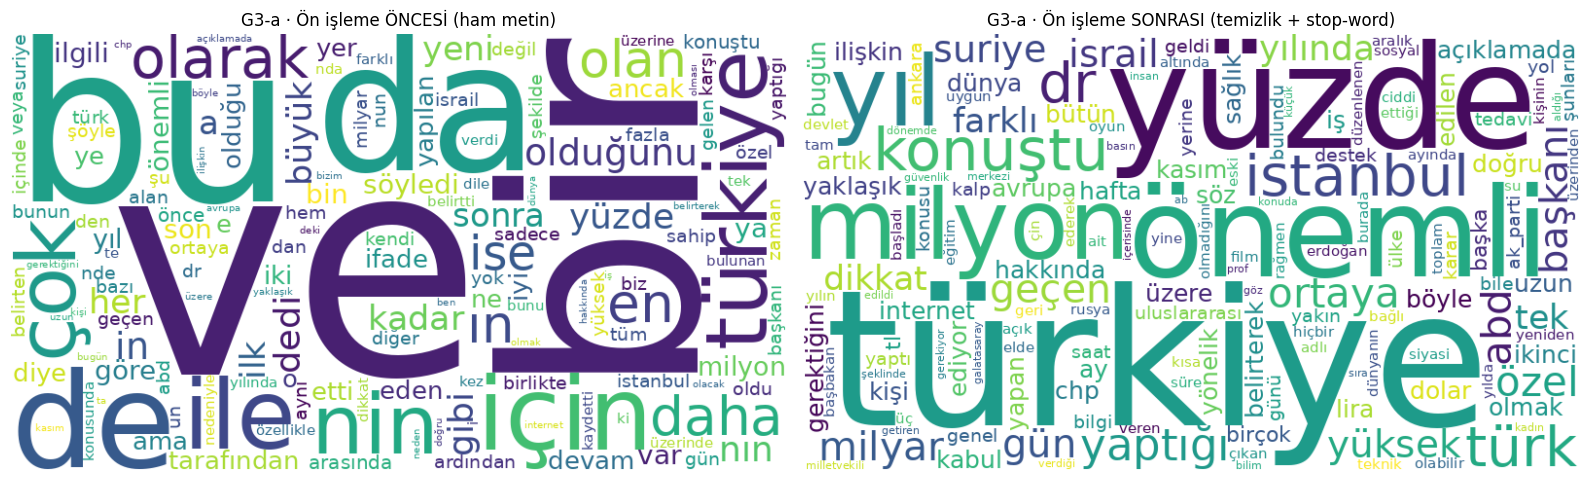

In [14]:
# ------------------------------------------------------------------
# G3-a | Bu hücrede ön işleme öncesi ve sonrası
# metinlerden iki kelime bulutu, Türkçe karakter destekli yazı tipiyle yan yana çizilir.
# ------------------------------------------------------------------
from wordcloud import WordCloud

def kelime_bulutu(metin, baslik, ax):
    bulut = WordCloud(width=800, height=450, background_color="white", font_path=TURKCE_FONT,
                      stopwords=set(),            # wordcloud'un İngilizce stop listesi devre dışı
                      collocations=False,         # iki kelimelik öbekler ayrıca eklenmesin
                      max_words=150, random_state=SEED).generate(metin)
    ax.imshow(bulut, interpolation="bilinear"); ax.set_title(baslik); ax.axis("off")

ham_birlesik = " ".join(df["metin"].map(turkce_kucuk_harf))
islenmis_birlesik = " ".join(df["islenmis_govdesiz"])

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
kelime_bulutu(ham_birlesik, "G3-a · Ön işleme ÖNCESİ (ham metin)", axes[0])
kelime_bulutu(islenmis_birlesik, "G3-a · Ön işleme SONRASI (temizlik + stop-word)", axes[1])
plt.tight_layout(); plt.show()

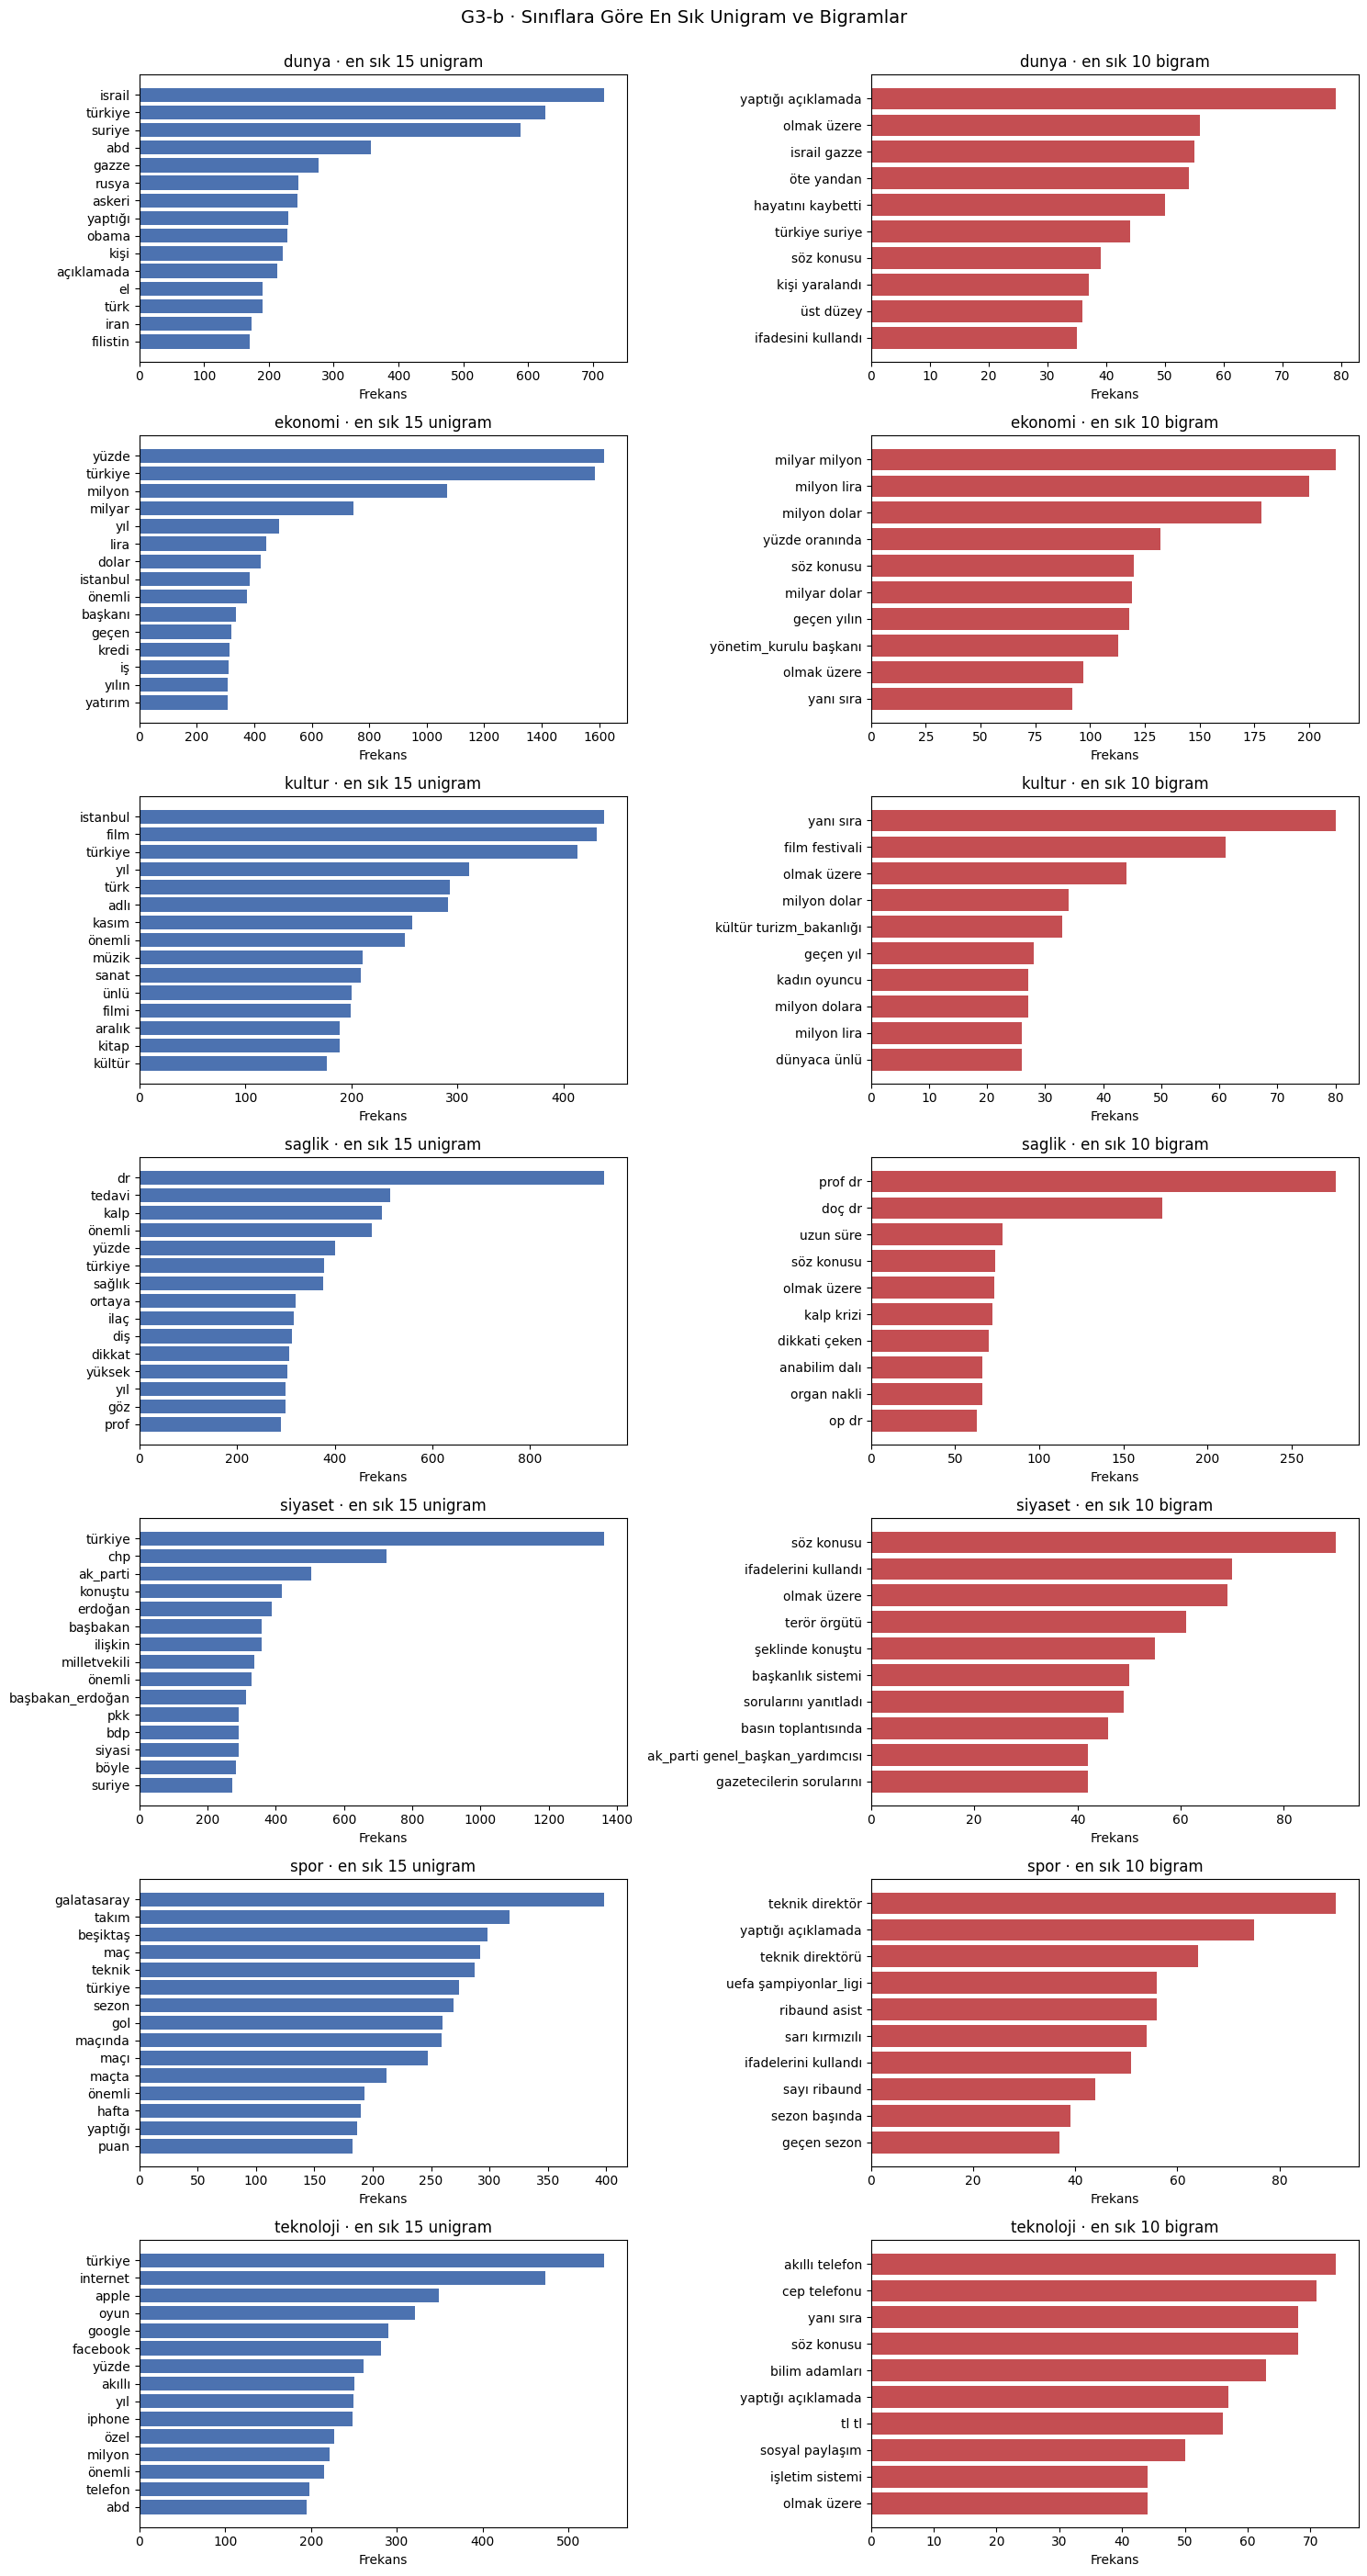

In [15]:
# ------------------------------------------------------------------
# G3-b | Bu hücrede her sınıf için en sık 15 unigram ve en sık 10 bigram
# hesaplanır ve çubuk grafiklerle (her sınıf bir satır) gösterilir.
# ------------------------------------------------------------------
def ngram_say(token_listeleri, n):
    # Her metin içinde ardışık n kelimelik öbekler sayılır (metin sınırları aşılmaz)
    sayac = Counter()
    for tokenlar in token_listeleri:
        sayac.update(zip(*[tokenlar[i:] for i in range(n)]))
    return sayac

KATEGORILER = sorted(df["kategori"].unique())
df["tokenlar"] = df["islenmis_govdesiz"].str.split()   # tekrar kullanılacak token listeleri

fig, axes = plt.subplots(len(KATEGORILER), 2, figsize=(15, 4 * len(KATEGORILER)))
for satir, kat in enumerate(KATEGORILER):
    tokenlar = df.loc[df["kategori"] == kat, "tokenlar"]
    uni = ngram_say(tokenlar, 1).most_common(15)
    bi = ngram_say(tokenlar, 2).most_common(10)
    axes[satir, 0].barh([w[0] for w, _ in uni][::-1], [c for _, c in uni][::-1], color="#4C72B0")
    axes[satir, 0].set_title(f"{kat} · en sık 15 unigram"); axes[satir, 0].set_xlabel("Frekans")
    axes[satir, 1].barh([" ".join(w) for w, _ in bi][::-1], [c for _, c in bi][::-1], color="#C44E52")
    axes[satir, 1].set_title(f"{kat} · en sık 10 bigram"); axes[satir, 1].set_xlabel("Frekans")
plt.suptitle("G3-b · Sınıflara Göre En Sık Unigram ve Bigramlar", fontsize=14, y=1.0)
plt.tight_layout(); plt.show()

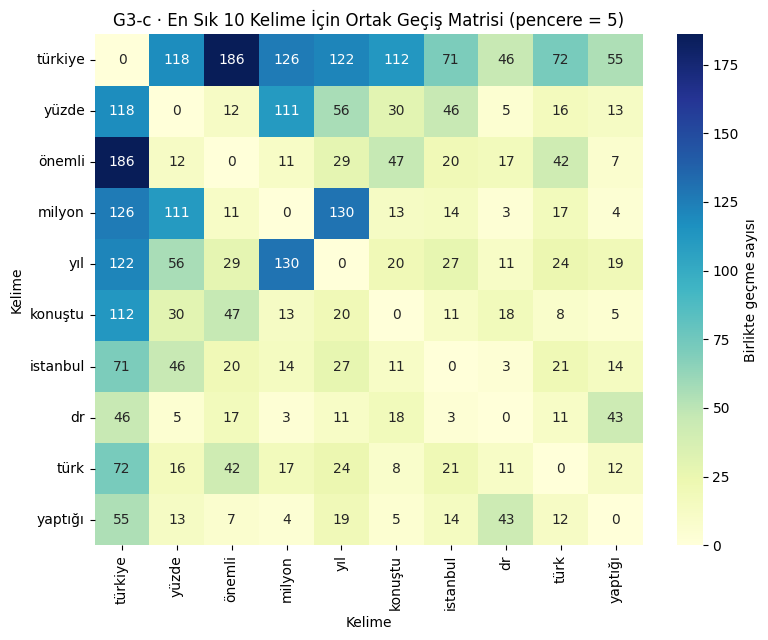

En sık birlikte geçen 5 çift: [('türkiye', 'önemli', np.int64(186)), ('milyon', 'yıl', np.int64(130)), ('türkiye', 'milyon', np.int64(126)), ('türkiye', 'yıl', np.int64(122)), ('türkiye', 'yüzde', np.int64(118))]


In [16]:
# ------------------------------------------------------------------
# G3-c | Bu hücrede en sık 10 kelime için pencere boyutu 5 olan ortak geçiş
# (co-occurrence) matrisi oluşturulur ve ısı haritası olarak çizilir. Pencere boyutu 5: art arda gelen 5 token
# içinde birlikte geçen her kelime çifti sayılır (aralarındaki uzaklık <= 4).
# Matris simetriktir; köşegen (kelimenin kendisiyle) sıfır bırakılır.
# ------------------------------------------------------------------
PENCERE = 5
genel_sayac = Counter(t for tokenlar in df["tokenlar"] for t in tokenlar)
en_sik_10 = [w for w, _ in genel_sayac.most_common(10)]
indeks = {w: i for i, w in enumerate(en_sik_10)}
ortak = np.zeros((10, 10), dtype=int)

for tokenlar in df["tokenlar"]:
    for i, w1 in enumerate(tokenlar):
        if w1 not in indeks:
            continue
        for w2 in tokenlar[i + 1 : i + PENCERE]:      # sağdaki en fazla 4 komşu
            if w2 in indeks and w2 != w1:
                ortak[indeks[w1], indeks[w2]] += 1
                ortak[indeks[w2], indeks[w1]] += 1    # simetri

ortak_df = pd.DataFrame(ortak, index=en_sik_10, columns=en_sik_10)
plt.figure(figsize=(8, 6.5))
sns.heatmap(ortak_df, annot=True, fmt="d", cmap="YlGnBu", cbar_kws={"label": "Birlikte geçme sayısı"})
plt.title(f"G3-c · En Sık 10 Kelime İçin Ortak Geçiş Matrisi (pencere = {PENCERE})")
plt.xlabel("Kelime"); plt.ylabel("Kelime"); plt.tight_layout(); plt.show()

ust_ucgen = [(en_sik_10[i], en_sik_10[j], ortak[i, j]) for i in range(10) for j in range(i + 1, 10)]
print("En sık birlikte geçen 5 çift:", sorted(ust_ucgen, key=lambda x: -x[2])[:5])

## G3 · Değerlendirme
- Ön işleme öncesindeki kelime bulutunda `ve`, `bir`, `bu`, `da`, `için` gibi işlev kelimeleri ve kopuk ekler (`nin`) baskındır. Ön işleme sonrasında ise `türkiye`, `yüzde`, `milyon`, `istanbul`, `dr`, `suriye`, `israil` gibi içerik kelimeleri öne çıkmıştır; bu da temizlik ve stop-word adımlarının amacına ulaştığını göstermektedir.
- Sınıf bazındaki unigramlar sınıfları belirgin biçimde ayırmaktadır: dünyada `israil`, `suriye`, `gazze`; ekonomide `yüzde`, `milyon`, `lira`; sağlıkta `dr`, `tedavi`, `kalp`; sporda `galatasaray`, `takım`, `maç`; teknolojide `internet`, `apple`, `google` en sık kelimeler arasındadır. `türkiye` kelimesi ise neredeyse tüm sınıflarda ilk sıralarda yer aldığından ayırt edici değildir; TF-IDF'in IDF bileşeni bu tür kelimelerin ağırlığını düşürmektedir.
- Bigramlar sınıfları daha da açık biçimde yansıtmaktadır (`prof dr`, `teknik direktör`, `akıllı telefon`, `terör örgütü`, `milyon dolar`). Öte yandan `söz konusu`, `olmak üzere`, `yaptığı açıklamada` gibi haber dili kalıpları her sınıfta görülmektedir. Bu durum, bigram özelliklerinin modele eklenmesi düşünülürse kalıp ifadelerin ayrıca filtrelenmesi gerektiğine işaret etmektedir.
- Ortak geçiş matrisinde en güçlü bağların `türkiye–önemli` (186), `milyon–yıl` (130), `türkiye–milyon` (126) ve `türkiye–yüzde` (118) çiftleri arasında olduğu görülmüştür. Bu çiftler ekonomi haberlerindeki "Türkiye … yüzde … milyon" kalıbını yansıtmaktadır. Ancak bu kelimeler zaten çok sık geçtiği için matristeki sayıların bir kısmı gerçek bir anlamsal ilişkiden çok yüksek frekanstan kaynaklanmaktadır.

---
## **G4 · Dilbilgisel Çözümleme**
---
Bu bölümde metinler kelime frekansının ötesinde, dilbilgisel açıdan çözümlenmektedir. Rastgele seçilen 50 cümle Stanza ile sözcük türlerine göre etiketlenmekte ve etiket dağılımları kategoriler arasında karşılaştırılmakta; seçilen üç cümlenin bağımlılık yapısı ise özne, nesne ve yüklem ilişkileri üzerinden yorumlanmaktadır. N-gram frekansları hesaplanmakta ve veride görülmeyen bir bigram için sıfır olasılık sorunu ile Laplace düzleştirmesinin etkisi sayısal olarak gösterilmektedir. Son olarak adlandırılmış varlık tanıma uygulanarak haberlerdeki kişi, yer ve kurum adları çıkarılmaktadır.

Sözde cümle havuzu: 3981 | seçilen: 50
Seçilen cümlelerin kategori dağılımı: {'saglik': 9, 'siyaset': 18, 'dunya': 5, 'teknoloji': 2, 'ekonomi': 8, 'kultur': 3, 'spor': 5}
Toplam etiketlenen kelime: 692


,kategori,kelime,lemma,UPOS
0,saglik,eczacılar,eczacı,NOUN
1,saglik,kategorisinde,kategori,NOUN
2,saglik,memduh,memduh,ADJ
3,saglik,ekinci,ekinci,NOUN
4,saglik,birinci,birinci,ADJ
5,saglik,ihsan,ihsan,NOUN
6,saglik,selçuk,selçuk,PROPN
7,saglik,ikinci,ikinci,ADJ
8,saglik,ve,ve,CCONJ
9,saglik,mete,mete,PROPN


kategori,dunya,ekonomi,kultur,saglik,siyaset,spor,teknoloji
UPOS,,,,,,,
NOUN,47.6,39.6,34.2,38.6,41.5,23.6,50.0
VERB,20.6,20.8,18.4,22.0,24.5,27.0,15.4
ADJ,9.5,8.3,15.8,11.0,6.3,11.2,11.5
PROPN,9.5,3.1,10.5,12.6,9.1,7.9,3.8
NUM,3.2,9.4,2.6,2.4,2.8,11.2,7.7
CCONJ,3.2,3.1,7.9,6.3,5.9,5.6,3.8
ADV,0.0,5.2,10.5,0.8,1.2,9.0,7.7
ADP,4.8,4.2,0.0,3.9,2.8,1.1,0.0
DET,1.6,6.2,0.0,1.6,2.8,1.1,0.0


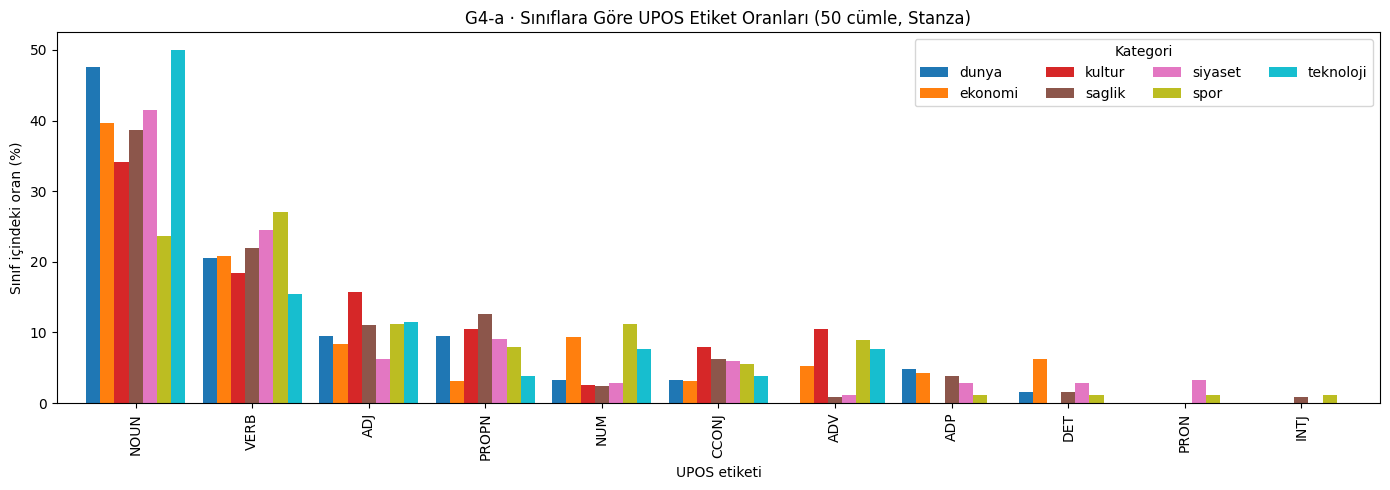

In [17]:
# ------------------------------------------------------------------
# G4-a | Bu hücrede rastgele (tohum 42) seçilen 50 cümle Stanza ile POS
# etiketlenir; UPOS etiketlerinin oranları sınıflara göre karşılaştırılır.
# ------------------------------------------------------------------
def turkce_baslik(kelime):
    # Türkçe büyük harf: i->İ, ı->I kuralına uyarak yalnızca ilk harf büyütülür
    ilk = {"i": "İ", "ı": "I"}.get(kelime[:1], kelime[:1].upper())
    return ilk + kelime[1:]

def stanza_icin_hazirla(cumle):
    # Rakam/özel karakter kalıntıları atılır; alt çizgili özel adlar ayrılıp baş harfleri büyütülür
    temiz = re.sub(r"[^a-zçğıöşüâîû_0-9\s]", " ", turkce_kucuk_harf(cumle))
    tokenlar = []
    for tok in temiz.split():
        if "_" in tok:
            tokenlar.extend(turkce_baslik(p) for p in tok.split("_") if p)
        else:
            tokenlar.append(tok)
    return tokenlar

# Her metinden sözde cümleler çıkarılır, (cümle, kategori) çiftleri havuzda toplanır
havuz = [(c, kat) for metin, kat in zip(df["metin"], df["kategori"]) for c in sozde_cumle_bol(metin, 6, 20)]
rastgele = random.Random(SEED)                         # tohum 42 ile yerel üreteç
secilen_50 = rastgele.sample(havuz, 50)
print("Sözde cümle havuzu:", len(havuz), "| seçilen:", len(secilen_50))
print("Seçilen cümlelerin kategori dağılımı:", dict(Counter(k for _, k in secilen_50)))

pos_doc = nlp_stanza([stanza_icin_hazirla(c) for c, _ in secilen_50])
pos_kayitlari = [{"kategori": kat, "kelime": w.text, "lemma": w.lemma, "UPOS": w.upos}
                 for (c, kat), cumle in zip(secilen_50, pos_doc.sentences) for w in cumle.words]
pos_df = pd.DataFrame(pos_kayitlari)
print("Toplam etiketlenen kelime:", len(pos_df))
display(pos_df.head(12))

# Sınıf içi oranlar (%): cümle sayıları sınıflar arasında farklı olduğundan ham sayı yerine oran kullanılır
upos_oran = (pd.crosstab(pos_df["UPOS"], pos_df["kategori"], normalize="columns") * 100).round(1)
upos_oran = upos_oran.loc[upos_oran.mean(axis=1).sort_values(ascending=False).index]
display(upos_oran)

ax = upos_oran.plot(kind="bar", figsize=(14, 5), width=0.85, colormap="tab10")
ax.set_title("G4-a · Sınıflara Göre UPOS Etiket Oranları (50 cümle, Stanza)")
ax.set_xlabel("UPOS etiketi"); ax.set_ylabel("Sınıf içindeki oran (%)")
ax.legend(title="Kategori", ncol=4); plt.tight_layout(); plt.show()

In [18]:
# ------------------------------------------------------------------
# G4-b | Bu hücrede 3 cümlenin bağımlılık çözümlemesi (ID, sözcük, lemma, POS,
# baş, ilişki) tablo hâlinde gösterilir. Yorumlanabilirlik için 50 cümle içinden
# farklı kategorilere ait, 6–12 kelimelik ve özne (nsubj) içeren ilk 3 cümle seçilir.
# root, nsubj ve obj/obl ilişkileri her cümle için otomatik özetlenir.
# ------------------------------------------------------------------
def bagimlilik_tablosu(cumle):
    satirlar = []
    for w in cumle.words:
        bas = cumle.words[w.head - 1].text if w.head > 0 else "ROOT"
        satirlar.append({"ID": w.id, "Sözcük": w.text, "Lemma": w.lemma, "POS": w.upos,
                         "Baş (ID)": w.head, "Baş sözcük": bas, "İlişki": w.deprel})
    return pd.DataFrame(satirlar)

secilen_3, kullanilan_kat = [], set()
for (c, kat), cumle in zip(secilen_50, pos_doc.sentences):
    iliskiler = {w.deprel for w in cumle.words}
    if kat not in kullanilan_kat and 6 <= len(cumle.words) <= 12 and "nsubj" in iliskiler:
        secilen_3.append((kat, cumle)); kullanilan_kat.add(kat)
    if len(secilen_3) == 3:
        break
# Yeterli cümle bulunamazsa kalan kısa cümlelerle tamamlanır
for (c, kat), cumle in zip(secilen_50, pos_doc.sentences):
    if len(secilen_3) == 3: break
    if all(cumle is not s for _, s in secilen_3) and len(cumle.words) <= 12:
        secilen_3.append((kat, cumle))

for no, (kat, cumle) in enumerate(secilen_3, 1):
    print(f"\nCümle {no} [{kat}]: {' '.join(w.text for w in cumle.words)}")
    display(bagimlilik_tablosu(cumle))
    kok = [w.text for w in cumle.words if w.deprel == "root"]
    ozne = [w.text for w in cumle.words if w.deprel.startswith("nsubj")]
    nesne = [w.text for w in cumle.words if w.deprel == "obj"]
    tumlec = [w.text for w in cumle.words if w.deprel.startswith("obl")]
    print(f"  root: {kok} | nsubj: {ozne} | obj: {nesne or '-'} | obl: {tumlec or '-'}")


Cümle 1 [siyaset]: bağış fransa da öldürülen pkk lı kadınlarla ilgili değerlendirmede de bulundu


,ID,Sözcük,Lemma,POS,Baş (ID),Baş sözcük,İlişki
0,1,bağış,bağış,NOUN,2,fransa,nmod
1,2,fransa,fransa,PROPN,4,öldürülen,nsubj
2,3,da,da,CCONJ,2,fransa,advmod:emph
3,4,öldürülen,öl,VERB,7,kadınlarla,acl
4,5,pkk,pkk,NOUN,7,kadınlarla,amod
5,6,lı,li,ADP,5,pkk,case
6,7,kadınlarla,kadın,ADJ,9,değerlendirmede,amod
7,8,ilgili,ilgili,ADJ,7,kadınlarla,amod
8,9,değerlendirmede,değerlen,VERB,11,bulundu,nmod
9,10,de,de,CCONJ,9,değerlendirmede,advmod:emph


  root: ['bulundu'] | nsubj: ['fransa'] | obj: - | obl: -

Cümle 2 [saglik]: kahveci organ bağışı fazla olmadığında kadavradan organ temin edilemiyor dedi


,ID,Sözcük,Lemma,POS,Baş (ID),Baş sözcük,İlişki
0,1,kahveci,kahveci,NOUN,3,bağışı,nmod:poss
1,2,organ,organ,NOUN,3,bağışı,nmod:poss
2,3,bağışı,bağış,NOUN,5,olmadığında,nsubj
3,4,fazla,fazla,ADJ,5,olmadığında,amod
4,5,olmadığında,ol,VERB,8,temin,advcl
5,6,kadavradan,kadavra,NOUN,8,temin,nmod
6,7,organ,organ,NOUN,8,temin,obj
7,8,temin,temin,NOUN,10,dedi,ccomp
8,9,edilemiyor,et,VERB,8,temin,compound:lvc
9,10,dedi,de,VERB,0,ROOT,root


  root: ['dedi'] | nsubj: ['bağışı'] | obj: ['organ'] | obl: -

Cümle 3 [teknoloji]: söz konusu açık İnternet Explorer 6 7 ve 8 sürümlerinde bulunuyor


,ID,Sözcük,Lemma,POS,Baş (ID),Baş sözcük,İlişki
0,1,söz,söz,NOUN,2,konusu,nmod:poss
1,2,konusu,konu,NOUN,3,açık,nsubj
2,3,açık,açık,ADJ,4,İnternet,amod
3,4,İnternet,internet,NOUN,11,bulunuyor,nsubj
4,5,Explorer,Explorer,PROPN,4,İnternet,flat
5,6,6,yirmibeş,NUM,4,İnternet,flat
6,7,7,trilyon,NUM,4,İnternet,flat
7,8,ve,ve,CCONJ,9,8,cc
8,9,8,lira,NOUN,10,sürümlerinde,nmod:poss
9,10,sürümlerinde,sürüm,NOUN,11,bulunuyor,nmod


  root: ['bulunuyor'] | nsubj: ['konusu', 'İnternet'] | obj: - | obl: -


In [19]:
# ------------------------------------------------------------------
# G4-c | Bu hücrede unigram, bigram ve trigram frekansları hesaplanır, en sık
# 10 trigram listelenir. Ardından veride hiç görülmeyen bir bigram için
# MLE olasılığının neden sıfır olduğu ve Laplace (add-one) düzleştirmesinin
# etkisi sayısal olarak gösterilir:
#   P_MLE(w2|w1)     = C(w1 w2) / C(w1)
#   P_Laplace(w2|w1) = (C(w1 w2) + 1) / (C(w1) + V)    V: sözlük boyutu
# ------------------------------------------------------------------
unigram = ngram_say(df["tokenlar"], 1)
bigram = ngram_say(df["tokenlar"], 2)
trigram = ngram_say(df["tokenlar"], 3)
V = len(unigram)
print(f"Farklı unigram (V): {V:,} | farklı bigram: {len(bigram):,} | farklı trigram: {len(trigram):,}")

display(pd.DataFrame([(" ".join(t), c) for t, c in trigram.most_common(10)],
                     columns=["Trigram", "Frekans"]))

def olasiliklar(w1, w2):
    c12, c1 = bigram[(w1, w2)], unigram[(w1,)]
    return c12, c1, c12 / c1, (c12 + 1) / (c1 + V)

# Görülmüş bir bigram ve aynı ilk kelimeyle başlayan, hiç görülmemiş bir bigram
gorulen = ("milli", "takım")
gorulmeyen = ("milli", "kanser")
satirlar = []
for w1, w2 in [gorulen, gorulmeyen]:
    c12, c1, p_mle, p_lap = olasiliklar(w1, w2)
    satirlar.append({"Bigram": f"{w1} {w2}", "C(w1 w2)": c12, "C(w1)": c1, "V": V,
                     "P_MLE": round(p_mle, 6), "P_Laplace": round(p_lap, 6)})
display(pd.DataFrame(satirlar))
c12, c1, _, _ = olasiliklar(*gorulmeyen)
print(f"'{' '.join(gorulmeyen)}' için MLE: {c12}/{c1} = 0 -> bu bigramı içeren her cümlenin olasılığı 0 olur.")
print(f"Laplace: ({c12}+1)/({c1}+{V}) = {(c12+1)/(c1+V):.2e} -> küçük ama sıfır olmayan bir olasılık.")
c12g, c1g, pm, pl = olasiliklar(*gorulen)
print(f"Bedeli: görülmüş '{' '.join(gorulen)}' bigramının olasılığı {pm:.4f} -> {pl:.6f} değerine düşer "
      f"(olasılık kütlesi görülmeyen bigramlara aktarılır).")

Farklı unigram (V): 109,014 | farklı bigram: 648,299 | farklı trigram: 766,148


,Trigram,Frekans
0,başta olmak üzere,114
1,muhabirine yaptığı açıklamada,91
2,milyar milyon lira,74
3,milyar milyon dolar,66
4,düzenlediği basın toplantısında,64
5,öğretim üyesi_prof dr,63
6,geçen yılın dönemine,54
7,dahil olmak üzere,42
8,dalı öğretim üyesi_prof,42
9,geçen yılın ayına,41


,Bigram,C(w1 w2),C(w1),V,P_MLE,P_Laplace
0,milli takım,14,291,109014,0.04811,0.000137
1,milli kanser,0,291,109014,0.00000,0.000009


'milli kanser' için MLE: 0/291 = 0 -> bu bigramı içeren her cümlenin olasılığı 0 olur.
Laplace: (0+1)/(291+109014) = 9.15e-06 -> küçük ama sıfır olmayan bir olasılık.
Bedeli: görülmüş 'milli takım' bigramının olasılığı 0.0481 -> 0.000137 değerine düşer (olasılık kütlesi görülmeyen bigramlara aktarılır).


In [20]:
# ------------------------------------------------------------------
# G4-d | Bu hücrede adlandırılmış varlık tanıma (NER) uygulanır. Stanza'nın
# Türkçe NER modeli (Starlang) kullanılır; yüklenemezse yönergede önerilen
# Hugging Face modeline (savasy/bert-base-turkish-ner-cased) geçilir.
# Girdi: rastgele 150 haberin ilk 60 kelimesi (özel ad bilgisi geri kazandırılmış hâliyle).
# ------------------------------------------------------------------
TUR_ESLEME = {"PERSON": "PER", "PER": "PER", "LOCATION": "LOC", "LOC": "LOC",
              "ORGANIZATION": "ORG", "ORG": "ORG"}

ner_ornek = df.sample(150, random_state=SEED)
ner_girdileri = [stanza_icin_hazirla(" ".join(m.split()[:60])) for m in ner_ornek["metin"]]

varliklar = []
if "ner" in nlp_stanza.processors:
    NER_KAYNAGI = "Stanza (Starlang Türkçe NER)"
    ner_doc = nlp_stanza(ner_girdileri)
    for kat, cumle in zip(ner_ornek["kategori"], ner_doc.sentences):
        for ent in cumle.ents:
            varliklar.append({"Varlık": ent.text, "Tür": TUR_ESLEME.get(ent.type, ent.type), "kategori": kat})
else:
    from transformers import pipeline
    NER_KAYNAGI = "Hugging Face (savasy/bert-base-turkish-ner-cased)"
    ner_hf = pipeline("token-classification", model="savasy/bert-base-turkish-ner-cased",
                      aggregation_strategy="simple", device=-1)
    for kat, tokenlar in zip(ner_ornek["kategori"], ner_girdileri):
        for ent in ner_hf(" ".join(tokenlar)):
            varliklar.append({"Varlık": ent["word"], "Tür": TUR_ESLEME.get(ent["entity_group"], ent["entity_group"]),
                              "kategori": kat})

varlik_df = pd.DataFrame(varliklar)
print("NER kaynağı:", NER_KAYNAGI, "| bulunan varlık sayısı:", len(varlik_df))
print("Tür dağılımı:", varlik_df["Tür"].value_counts().to_dict())

# Her tür için en sık 10 varlık yan yana tablo hâlinde
tablolar = {}
for tur in ["PER", "LOC", "ORG"] + sorted(set(varlik_df["Tür"]) - {"PER", "LOC", "ORG"}):
    en_sik = varlik_df.loc[varlik_df["Tür"] == tur, "Varlık"].value_counts().head(10)
    tablolar[tur] = [f"{v} ({s})" for v, s in en_sik.items()] + [""] * (10 - len(en_sik))
display(pd.DataFrame(tablolar, index=range(1, 11)))

NER kaynağı: Stanza (Starlang Türkçe NER) | bulunan varlık sayısı: 424
Tür dağılımı: {'ORG': 113, 'PER': 108, 'LOC': 100, 'TIME': 84, 'MONEY': 19}


,PER,LOC,ORG,MONEY,TIME
1,Peter Jackson (4),abd (10),mcafee (3),3 doların (2),2013 (6)
2,Edward Gorey (4),ingiltere (4),Dead Space (3),170 milyon euroya (2),2012 (4)
3,billy scott (3),yunanistan (4),Milli Eğitim müdürlüğü (2),30 milyon euro (1),28 Ekim Pazar (2)
4,Vlad Filat (3),fransa (4),Şampiyonlar Ligi (2),178 milyar dolarlık (1),29 ekim (2)
5,Ünal Aysal (3),almanya (4),Google Glass (2),83 milyar dolar (1),11 2012 (2)
6,John Mcafee (3),Moldova (3),Tbmm İnsan Haklarını İnceleme Komisyonu (2),5 milyar 720 milyon dolar (1),2013 yılında (2)
7,Hüseyin Aygün (2),Real Madrid (3),landsat (2),5 milyar 640 milyon dolar (1),2011 yılında (2)
8,phil lynott (2),moldova (3),İşçi Partisi (2),170 milyon euro (1),2013 yılından (2)
9,Mark Rutte (2),Güney Kore (3),Modern Warfare (2),1 doların (1),2014 (2)
10,John Steinbeck (2),finlandiya (2),Sağlık Bakanlığı (2),3 dolarlık (1),1925 yılında (2)


In [21]:
# ------------------------------------------------------------------
# G4-d (hata analizi) | Bu hücrede NER hatalarını Türkçenin yapısıyla
# ilişkilendirmek için kontrollü bir deney yapılır: aynı cümle (1) doğru yazımla,
# (2) veri setindeki biçimde (küçük harf + kesme işaretiyle kopan ek) verilir.
# Ayrıca veride bulunan şüpheli varlıklar (kopuk ek içeren, küçük harfle başlayan,
# tek harfli) listelenir.
# ------------------------------------------------------------------
def ner_uygula(tokenlar):
    if "ner" in nlp_stanza.processors:
        return [(e.text, e.type) for e in nlp_stanza([tokenlar]).sentences[0].ents]
    return [(e["word"], e["entity_group"]) for e in ner_hf(" ".join(tokenlar))]

deney = {
    "Doğru yazım": "MHP'nin Genel Başkanı Devlet Bahçeli Ankara'da Türkiye'nin sorunlarını anlattı",
    "Veri biçimi (küçük harf, kopuk ek)": "mhp nin genel başkanı devlet bahçeli ankara da türkiye nin sorunlarını anlattı",
    "Veri biçimi + özel ad geri kazanımı": "mhp nin genel başkanı Devlet Bahçeli ankara da türkiye nin sorunlarını anlattı",
}
for ad, cumle in deney.items():
    tokenlar = word_tokenize(cumle, language="turkish") if "'" in cumle else cumle.split()
    print(f"{ad:38s} -> {ner_uygula(tokenlar)}")

# Şüpheli varlıklar: kopuk ek içeren, küçük harfle başlayan ya da çok kısa olanlar
supheli = varlik_df[varlik_df["Varlık"].apply(
    lambda v: any(p in KOPUK_EKLER for p in v.lower().split()) or v[:1].islower() or len(v) <= 2)]
print(f"\nŞüpheli varlık sayısı: {len(supheli)} / {len(varlik_df)}")
display(supheli["Varlık"].value_counts().head(10).rename_axis("Şüpheli varlık").reset_index(name="Sayı"))

Doğru yazım                            -> [("Ankara'da", 'LOCATION')]
Veri biçimi (küçük harf, kopuk ek)     -> []
Veri biçimi + özel ad geri kazanımı    -> []

Şüpheli varlık sayısı: 135 / 424


,Şüpheli varlık,Sayı
0,abd,11
1,yunanistan,4
2,ingiltere,4
3,fransa,4
4,almanya,4
5,moldova,3
6,pearl harbor,3
7,mcafee,3
8,billy scott,3
9,meksika,2


## G4 · Değerlendirme
- **POS (G4-a):** 50 cümledeki 692 kelimede tüm sınıflarda en sık etiketin NOUN (%24–50), ardından VERB (%15–27) olduğu görülmüştür. Bu, haber dilinin isim ağırlıklı yapısıyla uyumludur. Sınıflar arasında anlamlı farklar da gözlenmiştir: spor cümlelerinde maç anlatımları nedeniyle VERB (%27) ve skorlar nedeniyle NUM (%11,2) oranı en yüksektir; ekonomide de sayısal ifadeler nedeniyle NUM oranı (%9,4) yüksektir. Bununla birlikte, metinler küçük harfli olduğu için `memduh`, `ekinci`, `ihsan` gibi kişi adları ADJ veya NOUN olarak etiketlenmiş ve PROPN oranı olduğundan düşük ölçülmüştür. Ayrıca rastgele seçimde sınıflar dengesiz dağılmıştır (siyaset 18, teknoloji 2 cümle); bu yüzden az örnekli sınıflardaki oranlar güvenilir değildir.
- **Bağımlılık (G4-b):** Türkçe SOV dizilimli bir dil olduğundan üç cümlede de `root` olarak cümle sonundaki çekimli yüklem (`bulundu`, `dedi`, `bulunuyor`) doğru bulunmuştur.
  - **Cümle 1** (*bağış fransa da öldürülen pkk lı kadınlarla ilgili değerlendirmede de bulundu*): Gerçek özne, küçük harfle yazılmış özel ad `bağış` (soyadı) olmasına rağmen nmod olarak etiketlenmiş; `nsubj` hatalı olarak `fransa` kelimesine atanmıştır. Kesme işaretiyle ayrılması gereken bulunma eki `da`, bağlaç `da` ile karıştırılmış (CCONJ, advmod:emph), kopuk ek `lı` ise ADP olarak etiketlenmiştir. Bu hatalar doğrudan veri setinin küçük harf ve kopuk ek yapısından kaynaklanmaktadır.
  - **Cümle 2** (*kahveci organ bağışı fazla olmadığında kadavradan organ temin edilemiyor dedi*): En başarılı çözümlemedir. Ana yüklem `dedi` root, aktarılan yan cümle `temin` ise `ccomp` olarak bağlanmış; `organ` kelimesi `temin etmek` eyleminin nesnesi (`obj`), `bağışı` ise zarf-fiil yan cümlesinin öznesi (`nsubj`) olarak doğru bulunmuştur. `temin edilemiyor` yapısı `compound:lvc` (hafif fiil birleşimi) olarak tanınmıştır. Ancak konuşan kişinin soyadı olan `kahveci` yine küçük harf nedeniyle ad tamlaması (`nmod:poss`) sanılmıştır.
  - **Cümle 3** (*söz konusu açık İnternet Explorer 6 7 ve 8 sürümlerinde bulunuyor*): Baş harfi büyütülen `İnternet Explorer` doğru biçimde birleşik ad (`flat`) olarak çözümlenmiş, ancak `konusu` ve `İnternet` birlikte `nsubj` sayılarak iki özne üretilmiştir. Rakamların lemmaları ise anlamsızdır (`6 → yirmibeş`, `8 → lira`).
  - Üç cümlede de ayrılma ve bulunma hâli eki alan isimler (`kadavradan`, `sürümlerinde`, `değerlendirmede`) `obl` yerine `nmod` olarak etiketlenmiştir. Türkçede dilbilgisel ilişkiler büyük ölçüde hâl ekleriyle kurulduğundan, kopuk ekler ve noktalama eksikliği çözümleyicinin başarısını doğrudan düşürmektedir.
- **N-gram (G4-c):** En sık trigramlar `başta olmak üzere` (114), `muhabirine yaptığı açıklamada` (91), `milyar milyon lira` (74) gibi haber dili kalıplarıdır. Veride hiç geçmeyen `milli kanser` bigramının MLE olasılığı 0/291 = **0**'dır; bu durumda zincir kuralıyla hesaplanan cümle olasılığının tamamı sıfıra iner. Laplace düzleştirmesi her sayıma 1, paydaya ise V = 109.014 ekleyerek bu olasılığı 9,15·10⁻⁶'ya çıkarmıştır. Bunun bedeli, görülmüş `milli takım` bigramının olasılığının 0,048'den 0,000137'ye, yani yaklaşık 350 kat düşmesidir. Türkçenin eklemeli yapısı sözlüğü çok büyüttüğü için add-one düzleştirmesi görülen olaylardan aşırı miktarda olasılık kütlesi çekmektedir.
- **NER (G4-d):** Stanza'nın Türkçe NER modeli 150 haberde 424 varlık bulmuştur (ORG 113, PER 108, LOC 100, TIME 84, MONEY 19). En sık varlıklar haberlerin konusu olan kişiler (`Peter Jackson`, `Mark Rutte`), ülkeler (`abd`, `ingiltere`) ve kurumlardır (`Sağlık Bakanlığı`). Türkçenin yapısıyla ilişkili iki temel hata gözlenmiştir:
  1. **Büyük harf bilgisinin kaybı:** Kontrollü deneyde model, doğru yazılmış cümlede yalnızca `Ankara'da` kelimesini bulmuş; `MHP` ve `Devlet Bahçeli`yi ise bulamamıştır. Aynı cümlenin küçük harfli ve kopuk ekli veri biçiminde ise hiçbir varlık tanınmamış, özel adın baş harflerinin büyütülmesi de sonucu değiştirmemiştir. Veride bulunan varlıkların 135'i (%32) küçük harfle başlamaktadır. `abd`, `yunanistan` gibi sık geçen ülke adları küçük harfle de tanınabilmiş, ancak daha az bilinen adlar tutarsız biçimde etiketlenmiştir (aynı ülke hem `Moldova` hem `moldova` olarak ayrı varlıklar hâlinde görünmektedir).
  2. **Eklemeli yapı ve varlık sınırları:** Varlık sınırları eki de kapsayacak şekilde çizilmiştir (`Ankara'da`, `3 doların`, `170 milyon euroya`). Bu durum, aynı varlığın farklı çekimlerinin ayrı varlıklar gibi sayılmasına yol açmaktadır. Bunun dışında tür karışıklıkları da görülmüştür: futbol kulübü `Real Madrid` LOC, video oyunları `Dead Space` ve `Modern Warfare` ise ORG olarak etiketlenmiş; `mcafee` hem kişi (John McAfee) hem şirket olabildiğinden ORG olarak işaretlenmiştir. Noktalama silindiği için tarihler de bozulmuştur (`11 2012`).

---
## **G5 · Metin Temsilleri**
---
Bu bölümde haber metinleri, makine öğrenmesi modellerinin işleyebileceği sayısal vektörlere dönüştürülmektedir. Önce BoW ve TF-IDF matrisleri oluşturulmakta, bu matrislerin boyutları ve seyreklik oranları raporlanmaktadır. TF-IDF yönteminin mantığını göstermek amacıyla seçilen bir terimin IDF değeri elle hesaplanmakta ve kütüphane sonucuyla karşılaştırılmaktadır. Ardından veri üzerinde bir Word2Vec modeli eğitilmekte; seçilen kelimelerin en yakın komşuları ve kelimeler arasındaki kosinüs benzerlikleri incelenmektedir. BoW ve TF-IDF için gövdelenmiş metinler, Word2Vec için ise daha okunabilir sonuçlar vermesi nedeniyle gövdelenmemiş metinler kullanılmıştır.

In [22]:
# ------------------------------------------------------------------
# G5-a | Bu hücrede BoW (CountVectorizer) ve TF-IDF (TfidfVectorizer) matrisleri
# oluşturulur, boyutları ve seyreklik oranları raporlanır.
# min_df=2: yalnızca tek bir metinde geçen (çoğunlukla yazım hatası/özel ad) terimler atılır.
# ------------------------------------------------------------------
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

bow_vektor = CountVectorizer(min_df=2)
X_bow = bow_vektor.fit_transform(df["islenmis"])
tfidf_vektor = TfidfVectorizer(min_df=2)          # varsayılanlar: smooth_idf=True, norm='l2'
X_tfidf = tfidf_vektor.fit_transform(df["islenmis"])

def seyreklik(X):
    return 100 * (1 - X.nnz / (X.shape[0] * X.shape[1]))   # sıfır olan hücrelerin yüzdesi

display(pd.DataFrame({
    "Temsil": ["BoW", "TF-IDF"],
    "Boyut (metin × terim)": [X_bow.shape, X_tfidf.shape],
    "Sıfır olmayan hücre": [X_bow.nnz, X_tfidf.nnz],
    "Seyreklik (%)": [round(seyreklik(X_bow), 3), round(seyreklik(X_tfidf), 3)],
    "Metin başına ort. farklı terim": [round(X_bow.nnz / X_bow.shape[0], 1)] * 2}))

,Temsil,Boyut (metin × terim),Sıfır olmayan hücre,Seyreklik (%),Metin başına ort. farklı terim
0,BoW,"(4539, 27886)",544785,99.57,120.0
1,TF-IDF,"(4539, 27886)",544785,99.57,120.0


In [23]:
# ------------------------------------------------------------------
# G5-b | Bu hücrede seçilen bir terim için IDF değeri elle hesaplanır ve
# TfidfVectorizer.idf_ ile karşılaştırılır (smooth_idf=True formülü):
#   IDF(t) = ln( (1 + N) / (1 + df(t)) ) + 1
# ------------------------------------------------------------------
TERIM = govdele("maç")                                     # gövdelenmiş sözlükteki karşılığı
sutun = tfidf_vektor.vocabulary_[TERIM]
N = X_tfidf.shape[0]                                       # toplam belge sayısı
df_t = int((X_bow[:, sutun] > 0).sum())                    # terimi içeren belge sayısı
idf_elle = np.log((1 + N) / (1 + df_t)) + 1
idf_sklearn = tfidf_vektor.idf_[sutun]

print(f"Terim: '{TERIM}' | N = {N} | df(t) = {df_t}")
print(f"Elle  : ln((1+{N})/(1+{df_t})) + 1 = {idf_elle:.6f}")
print(f"sklearn idf_                      = {idf_sklearn:.6f}")
print("Eşit mi?", np.isclose(idf_elle, idf_sklearn))

# Karşılaştırma için çok yaygın ve çok nadir birer terim
for t in [govdele("türkiye"), govdele("kemoterapi")]:
    if t in tfidf_vektor.vocabulary_:
        j = tfidf_vektor.vocabulary_[t]
        print(f"  '{t}': df = {int((X_bow[:, j] > 0).sum())}, idf = {tfidf_vektor.idf_[j]:.3f}")

Terim: 'maç' | N = 4539 | df(t) = 430
Elle  : ln((1+4539)/(1+430)) + 1 = 3.354574
sklearn idf_                      = 3.354574
Eşit mi? True
  'türki': df = 1449, idf = 2.141
  'kemoterap': df = 10, idf = 7.023


In [24]:
# ------------------------------------------------------------------
# G5-c | Bu hücrede her sınıf için ortalama TF-IDF ağırlığı en yüksek 10 terim listelenir.
# ------------------------------------------------------------------
terimler = np.array(tfidf_vektor.get_feature_names_out())
ust_terimler = {}
for kat in KATEGORILER:
    maske = (df["kategori"] == kat).values
    ortalama = np.asarray(X_tfidf[maske].mean(axis=0)).ravel()   # sınıf içi ortalama ağırlık
    en_iyi = ortalama.argsort()[::-1][:10]
    ust_terimler[kat] = [f"{terimler[j]} ({ortalama[j]:.3f})" for j in en_iyi]
display(pd.DataFrame(ust_terimler, index=range(1, 11)))

,dunya,ekonomi,kultur,saglik,siyaset,spor,teknoloji
1,israil (0.044),yüz (0.044),film (0.061),hastalık (0.053),chp (0.037),maç (0.104),internet (0.032)
2,suri (0.042),türki (0.037),kitap (0.031),hasta (0.045),türki (0.031),tak (0.048),apple (0.030)
3,kiş (0.023),milyo (0.035),eser (0.031),dr (0.033),ak_parti (0.029),galatasaray (0.030),google (0.027)
4,asker (0.023),yıl (0.035),ödül (0.030),çocuk (0.032),milletvekil (0.027),sezo (0.027),telefo (0.026)
5,bölge (0.022),lira (0.032),konser (0.028),ilaç (0.032),kılıçdaroğlu (0.021),oyuncu (0.027),kullanıcı (0.026)
6,ülke (0.022),milyar (0.030),yıl (0.027),kanser (0.030),erdoğa (0.021),futbolcu (0.026),facebook (0.025)
7,türki (0.020),do (0.029),müzik (0.026),sağlık (0.028),terör (0.020),kulüp (0.026),oy (0.024)
8,saldırı (0.020),şirket (0.023),festival (0.024),kalp (0.028),süreç (0.020),puan (0.024),bilgisayar (0.023)
9,gazze (0.019),sektör (0.022),istanbul (0.024),bebek (0.026),başbakan_erdoğa (0.019),gol (0.024),kullanıç (0.022)
10,abd (0.019),satış (0.021),filmi (0.023),tedav (0.025),parti (0.019),ligi (0.023),ipho (0.022)


In [25]:
# ------------------------------------------------------------------
# G5-d | Bu hücrede veri üzerinde Word2Vec (Skip-gram) eğitilir:
# vector_size=64, sg=1, seed=42, workers=1 (yönerge). Ek olarak tam
# yeniden üretilebilirlik için Python'un oturuma göre değişen hash() fonksiyonu
# yerine sabit bir hash fonksiyonu (crc32) verilir.
# Kaynak: gensim Word2Vec belgeleri (radimrehurek.com/gensim/models/word2vec.html)
# ------------------------------------------------------------------
from gensim.models import Word2Vec

def sabit_hash(metin):
    return zlib.crc32(metin.encode("utf-8")) & 0xffffffff

t0 = time.time()
w2v = Word2Vec(sentences=df["tokenlar"].tolist(), vector_size=64, sg=1, seed=SEED, workers=1,
               window=5,          # her yönde 5 komşu kelime
               min_count=5,       # 5'ten az geçen kelimeler sözlüğe alınmaz
               epochs=10, hashfxn=sabit_hash)
print(f"Eğitim süresi: {time.time() - t0:.1f} sn | sözlük boyutu: {len(w2v.wv):,}")

KOMSU_KELIMELER = ["ekonomi", "futbol", "kanser"]
komsu_tablo = {}
for k in KOMSU_KELIMELER:
    komsu_tablo[k] = [f"{w} ({s:.2f})" for w, s in w2v.wv.most_similar(k, topn=5)]
display(pd.DataFrame(komsu_tablo, index=range(1, 6)))

Eğitim süresi: 76.7 sn | sözlük boyutu: 27,041


,ekonomi,futbol,kanser
1,hisarcıklıoğlu (0.76),basketbol (0.80),tedavisinde (0.80)
2,stratejileri (0.76),futbolu (0.76),parkinson (0.77)
3,türkiye_ab (0.74),voleybol (0.72),teşhisi (0.76)
4,politikaları (0.74),başantrenörü (0.72),hastalığının (0.76)
5,stefan_füle (0.74),takımlarının (0.72),psikiyatrik (0.75)


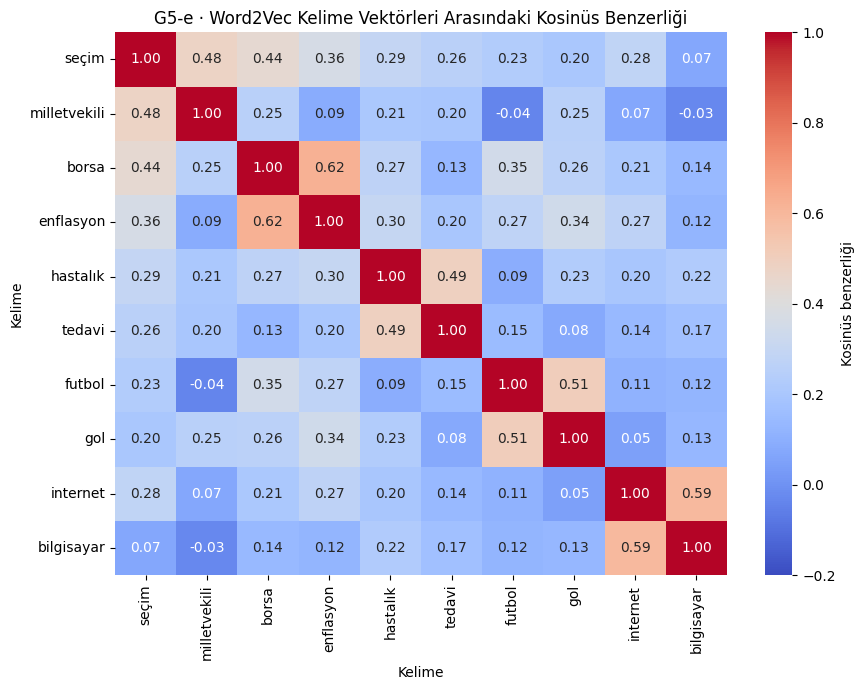

In [26]:
# ------------------------------------------------------------------
# G5-e | Bu hücrede seçilen 10 kelime arasındaki kosinüs benzerlikleri
# ısı haritasıyla gösterilir. Kelimeler bilinçli olarak 5 konudan ikişer seçilmiştir;
# iyi bir temsilde aynı konudaki çiftlerin benzerliği yüksek çıkmalıdır.
# ------------------------------------------------------------------
BENZERLIK_KELIMELERI = ["seçim", "milletvekili", "borsa", "enflasyon", "hastalık",
                        "tedavi", "futbol", "gol", "internet", "bilgisayar"]
mevcut = [k for k in BENZERLIK_KELIMELERI if k in w2v.wv]
benzerlik = pd.DataFrame([[w2v.wv.similarity(a, b) for b in mevcut] for a in mevcut],
                         index=mevcut, columns=mevcut)
plt.figure(figsize=(9, 7))
sns.heatmap(benzerlik, annot=True, fmt=".2f", cmap="coolwarm", vmin=-0.2, vmax=1,
            cbar_kws={"label": "Kosinüs benzerliği"})
plt.title("G5-e · Word2Vec Kelime Vektörleri Arasındaki Kosinüs Benzerliği")
plt.xlabel("Kelime"); plt.ylabel("Kelime"); plt.tight_layout(); plt.show()

## G5 · Değerlendirme
- BoW ve TF-IDF matrislerinin aynı boyutta (4.539 × 27.886) ve **%99,57 seyrek** olduğu görülmüştür. Her metin ortalama 120 farklı terim içermekte, yani sözlüğün yalnızca %0,4'ünü kullanmaktadır. Bu yüksek seyreklik, gövdelemeye rağmen Türkçenin eklemeli yapısının sözlüğü ne kadar büyüttüğünü göstermekte ve seyrek matris formatını zorunlu kılmaktadır.
- `maç` terimi için elle hesaplanan IDF değeri `ln((1+4539)/(1+430)) + 1 = 3,354574` olarak bulunmuş ve `TfidfVectorizer.idf_` değeriyle tam olarak eşleşmiştir. Karşılaştırma için çok yaygın `türki(ye)` terimi (df = 1.449) 2,141, nadir `kemoterap(i)` terimi (df = 10) ise 7,023 IDF almıştır. Bu sonuçlar, IDF'in her yerde geçen kelimeleri bastırıp nadir ve özgül terimleri öne çıkardığını göstermektedir.
- Sınıf bazında ortalama TF-IDF ağırlığı en yüksek terimler sınıfları açıkça tanımlamaktadır: sporda `maç` (0,104), `galatasaray`; sağlıkta `hastalık`, `hasta`, `dr`; teknolojide `internet`, `apple`, `google`; siyasette `chp`, `ak_parti`. Ekonomide `yüz` teriminin ilk sırada çıkması, Snowball'un `yüzde` kelimesini `yüz` gövdesine indirmesinden kaynaklanmaktadır; `do(lar)` gövdesi de aynı aşırı kesme sorununun bir örneğidir.
- Word2Vec komşuları büyük ölçüde anlamlıdır: `futbol` için `basketbol` (0,80) ve `voleybol`, `kanser` için `tedavisinde` (0,80), `teşhisi`, `parkinson` gibi aynı konu alanından kelimeler bulunmuştur. `ekonomi` kelimesinin `stratejileri` ve `politikaları` gibi anlamlı komşularının yanında `hisarcıklıoğlu` ve `stefan_füle` gibi özel adlar da listeye girmiştir. Bunun nedeni modelin anlamdan çok, yaklaşık 4.500 haberlik küçük derlemde **aynı haberlerde birlikte geçmeyi** öğrenmesidir.
- Kosinüs benzerliği ısı haritasında aynı konudaki çiftlerin benzerliği (`borsa–enflasyon` 0,68, `internet–bilgisayar` 0,54, `hastalık–tedavi` 0,53, `futbol–gol` 0,48, `seçim–milletvekili` 0,45) farklı konudaki çiftlerin çoğundan (genellikle 0,1–0,3) belirgin biçimde yüksektir; temsil konu yapısını yakalamaktadır. Ancak `seçim–borsa` (0,45) ve `enflasyon–gol` (0,42) gibi beklenenden yüksek değerler de görülmektedir. Bu istisnalar seçim dönemlerinde piyasaların haberleştirilmesi gibi birlikte geçme durumlarından ve küçük derlemin yarattığı gürültüden kaynaklanmaktadır.

---
## **G6 · Metin Sınıflandırma ve Değerlendirme**
---
Bu bölümde haber metinlerinin kategorisini tahmin eden sınıflandırıcılar eğitilmekte ve karşılaştırılmaktadır. Veri, sınıf oranları korunarak %80 eğitim ve %20 test kümesine ayrılmış; veri sızıntısını önlemek için vektörleştiriciler yalnızca eğitim kümesinde eğitilmiştir. Multinomial Naive Bayes, Lojistik Regresyon, Doğrusal SVM ve Random Forest modelleri BoW ve TF-IDF temsilleriyle ayrı ayrı denenerek toplam sekiz deney gerçekleştirilmektedir. Deneylerin sonuçları accuracy, precision, recall ve F1 ölçütleriyle tek bir tabloda toplanmaktadır. En başarılı model için sınıflandırma raporu ve karışıklık matrisi sunulmakta, yanlış sınıflandırılan örnekler üzerinden hata analizi yapılmaktadır.

In [27]:
# ------------------------------------------------------------------
# G6-a | Bu hücrede veri sınıf oranları korunarak %80 eğitim / %20 test olarak
# ayrılır. BoW ve TF-IDF vektörleştiricileri yalnızca eğitim verisinde fit edilir;
# test verisine yalnızca transform uygulanır.
# ------------------------------------------------------------------
X_train_metin, X_test_metin, y_train, y_test = train_test_split(
    df["islenmis"], df["kategori"], test_size=0.20, stratify=df["kategori"], random_state=SEED)
print("Eğitim:", X_train_metin.shape[0], "| Test:", X_test_metin.shape[0])
display(pd.DataFrame({"Eğitim": y_train.value_counts(), "Test": y_test.value_counts()}))

bow_g6 = CountVectorizer(min_df=2)
tfidf_g6 = TfidfVectorizer(min_df=2, sublinear_tf=True)    # sublinear_tf: tf yerine 1+log(tf); uzun metinlerin baskınlığını azaltır
temsiller = {
    "BoW": (bow_g6.fit_transform(X_train_metin), bow_g6.transform(X_test_metin)),
    "TF-IDF": (tfidf_g6.fit_transform(X_train_metin), tfidf_g6.transform(X_test_metin)),
}
for ad, (Xtr, Xte) in temsiller.items():
    print(f"{ad}: eğitim {Xtr.shape}, test {Xte.shape}")

Eğitim: 3631 | Test: 908


,Eğitim,Test
kategori,,
ekonomi,552,138
siyaset,552,138
dunya,541,136
teknoloji,517,130
spor,509,127
saglik,506,126
kultur,454,113


BoW: eğitim (3631, 24467), test (908, 24467)
TF-IDF: eğitim (3631, 24467), test (908, 24467)


In [28]:
# ------------------------------------------------------------------
# G6-b/c | Bu hücrede dört sınıflandırıcı (MNB, LR, Doğrusal SVM, Random Forest)
# iki temsil (BoW, TF-IDF) ile eğitilir: 4 × 2 = 8 deney. Her deney için accuracy,
# precision, recall ve F1 (macro) tek bir sonuç tablosunda toplanır.
# ------------------------------------------------------------------
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

modeller = {
    "Multinomial NB": MultinomialNB(alpha=0.1),
    "Lojistik Regresyon": LogisticRegression(max_iter=2000, C=10, random_state=SEED),
    "Doğrusal SVM": LinearSVC(C=1.0, random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED),
}

sonuclar, egitilmis = [], {}
for temsil_adi, (Xtr, Xte) in temsiller.items():           # BoW ve TF-IDF
    for model_adi, sablon in modeller.items():               # 4 sınıflandırıcı
        model = clone(sablon)                                 # her deney için temiz bir kopya
        t0 = time.time()
        model.fit(Xtr, y_train)                               # yalnızca eğitim verisi
        tahmin = model.predict(Xte)                           # test verisinde tahmin
        egitilmis[(temsil_adi, model_adi)] = (model, tahmin)
        sonuclar.append({
            "Temsil": temsil_adi, "Model": model_adi,
            "Accuracy": accuracy_score(y_test, tahmin),
            "Precision (macro)": precision_score(y_test, tahmin, average="macro"),
            "Recall (macro)": recall_score(y_test, tahmin, average="macro"),
            "F1 (macro)": f1_score(y_test, tahmin, average="macro"),
            "Süre (sn)": round(time.time() - t0, 2)})

sonuc_tablosu = pd.DataFrame(sonuclar).sort_values("F1 (macro)", ascending=False).reset_index(drop=True)
display(sonuc_tablosu.style.format({**{c: "{:.4f}" for c in ["Accuracy", "Precision (macro)",
                                                            "Recall (macro)", "F1 (macro)"]}, "Süre (sn)": "{:.2f}"})
        .background_gradient(subset=["F1 (macro)"], cmap="Greens"))

,Temsil,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro),Süre (sn)
0,TF-IDF,Doğrusal SVM,0.9119,0.9134,0.9138,0.9135,0.31
1,TF-IDF,Lojistik Regresyon,0.9097,0.9122,0.9109,0.9114,5.11
2,TF-IDF,Multinomial NB,0.8888,0.8943,0.8892,0.8906,0.06
3,BoW,Multinomial NB,0.8888,0.8923,0.8901,0.8901,0.04
4,BoW,Lojistik Regresyon,0.8789,0.8823,0.8796,0.8804,3.72
5,BoW,Random Forest,0.8778,0.8795,0.8796,0.8792,19.02
6,TF-IDF,Random Forest,0.8678,0.8693,0.8699,0.8692,18.21
7,BoW,Doğrusal SVM,0.8667,0.8691,0.8678,0.8675,1.57


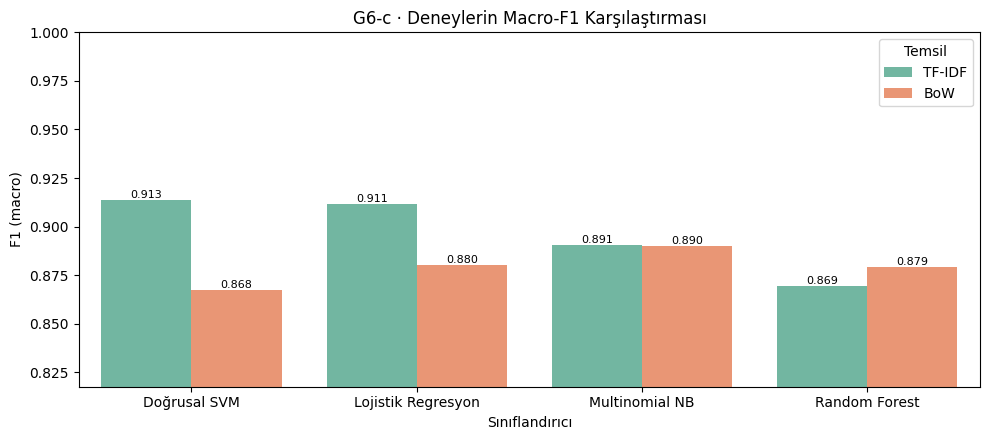

In [29]:
# ------------------------------------------------------------------
# G6-c | Bu hücrede 8 deneyin macro-F1 değerleri gruplu çubuk grafikle karşılaştırılır.
# ------------------------------------------------------------------
plt.figure(figsize=(10, 4.5))
ax = sns.barplot(data=sonuc_tablosu, x="Model", y="F1 (macro)", hue="Temsil", palette="Set2")
for kap in ax.containers:
    ax.bar_label(kap, fmt="%.3f", fontsize=8)
alt = sonuc_tablosu["F1 (macro)"].min() - 0.05
ax.set_ylim(max(0, alt), 1.0)
ax.set_title("G6-c · Deneylerin Macro-F1 Karşılaştırması")
ax.set_xlabel("Sınıflandırıcı"); ax.set_ylabel("F1 (macro)"); ax.legend(title="Temsil")
plt.tight_layout(); plt.show()

En iyi deney: Doğrusal SVM + TF-IDF (macro-F1 = 0.9135)

              precision    recall  f1-score   support

       dunya     0.8702    0.8382    0.8539       136
     ekonomi     0.8667    0.8478    0.8571       138
      kultur     0.9298    0.9381    0.9339       113
      saglik     0.9520    0.9444    0.9482       126
     siyaset     0.8936    0.9130    0.9032       138
        spor     0.9921    0.9843    0.9881       127
   teknoloji     0.8897    0.9308    0.9098       130

    accuracy                         0.9119       908
   macro avg     0.9134    0.9138    0.9135       908
weighted avg     0.9118    0.9119    0.9117       908



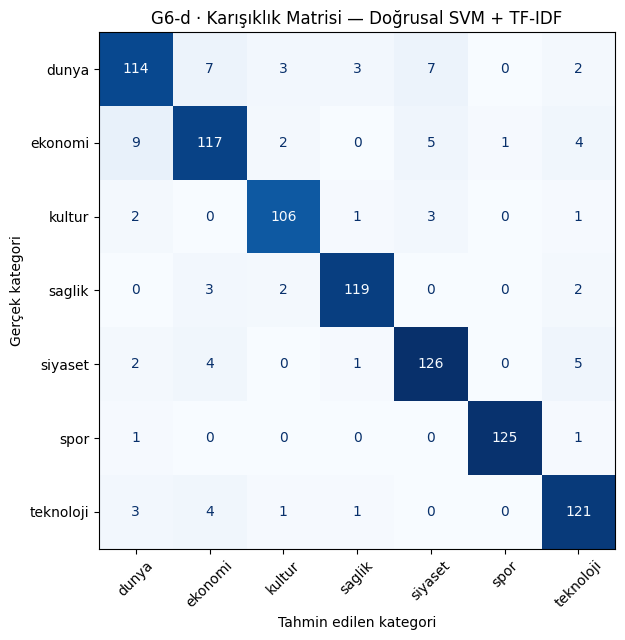

En çok karıştırılan (gerçek -> tahmin) çiftler: [('ekonomi', 'dunya', np.int64(9)), ('dunya', 'ekonomi', np.int64(7)), ('dunya', 'siyaset', np.int64(7)), ('ekonomi', 'siyaset', np.int64(5)), ('siyaset', 'teknoloji', np.int64(5))]


In [30]:
# ------------------------------------------------------------------
# G6-d | Bu hücrede macro-F1'e göre en iyi modelin sınıflandırma raporu ve
# karışıklık matrisi verilir.
# ------------------------------------------------------------------
en_iyi = sonuc_tablosu.iloc[0]
en_iyi_model, en_iyi_tahmin = egitilmis[(en_iyi["Temsil"], en_iyi["Model"])]
print(f"En iyi deney: {en_iyi['Model']} + {en_iyi['Temsil']} (macro-F1 = {en_iyi['F1 (macro)']:.4f})\n")
print(classification_report(y_test, en_iyi_tahmin, digits=4))

fig, ax = plt.subplots(figsize=(7.5, 6.5))
ConfusionMatrixDisplay.from_predictions(y_test, en_iyi_tahmin, labels=KATEGORILER, cmap="Blues",
                                        ax=ax, colorbar=False, xticks_rotation=45)
ax.set_title(f"G6-d · Karışıklık Matrisi — {en_iyi['Model']} + {en_iyi['Temsil']}")
ax.set_xlabel("Tahmin edilen kategori"); ax.set_ylabel("Gerçek kategori")
plt.tight_layout(); plt.show()

# En çok karıştırılan sınıf çiftleri
cm = confusion_matrix(y_test, en_iyi_tahmin, labels=KATEGORILER)
karisan = [(KATEGORILER[i], KATEGORILER[j], cm[i, j]) for i in range(len(cm)) for j in range(len(cm)) if i != j]
print("En çok karıştırılan (gerçek -> tahmin) çiftler:", sorted(karisan, key=lambda x: -x[2])[:5])

In [31]:
# ------------------------------------------------------------------
# G6-e | Bu hücrede en iyi modelin yanlış sınıflandırdığı örnekler yazdırılır.
# Hata nedenini anlamak için her örnekte modelin karar verirken en çok
# ağırlık verdiği 6 terim de gösterilir.
# ------------------------------------------------------------------
test_df = pd.DataFrame({"metin": df.loc[X_test_metin.index, "metin"], "gercek": y_test,
                        "tahmin": en_iyi_tahmin}, index=X_test_metin.index)
hatalar = test_df[test_df["gercek"] != test_df["tahmin"]]
print(f"Yanlış sınıflandırılan örnek sayısı: {len(hatalar)} / {len(test_df)}\n")

vektor = bow_g6 if en_iyi["Temsil"] == "BoW" else tfidf_g6
ozellik_adlari = np.array(vektor.get_feature_names_out())
sinif_listesi = list(en_iyi_model.classes_)

def etkili_terimler(indeks, sinif, n=6):
    # Doğrusal modellerde katkı = terim ağırlığı × katsayı; diğer modellerde metindeki en ağır terimler
    x = vektor.transform([df.loc[indeks, "islenmis"]])
    if hasattr(en_iyi_model, "coef_"):
        katki = x.multiply(en_iyi_model.coef_[sinif_listesi.index(sinif)]).toarray().ravel()
    elif hasattr(en_iyi_model, "feature_log_prob_"):
        katki = x.multiply(en_iyi_model.feature_log_prob_[sinif_listesi.index(sinif)]
                           - en_iyi_model.feature_log_prob_.mean(axis=0)).toarray().ravel()
    else:
        katki = x.toarray().ravel()
    return [ozellik_adlari[j] for j in katki.argsort()[::-1][:n] if katki[j] > 0]

for i, (indeks, satir) in enumerate(hatalar.sample(min(8, len(hatalar)), random_state=SEED).iterrows(), 1):
    print(f"--- Hata {i} | gerçek: {satir['gercek']} | tahmin: {satir['tahmin']}")
    print("Metin:", satir["metin"][:280], "...")
    print("Tahmini tetikleyen terimler:", etkili_terimler(indeks, satir["tahmin"]), "\n")

Yanlış sınıflandırılan örnek sayısı: 80 / 908

--- Hata 1 | gerçek: teknoloji | tahmin: ekonomi
Metin:  solucan gübresi üretim tesisi kurdular burdur da 2 girişimci organik atıklarla besledikleri solucanlardan gübre elde ediyor emekli öğretmen sadettin başak ve arkadaşı mehmet aksoy rusya dan getirdikleri solucanları organik atıklarla besleyerek solucan gübresi üretim tesisi kurdu ...
Tahmini tetikleyen terimler: ['organik', 'yüz', 'lira', 'atık', 'üret', 'su'] 

--- Hata 2 | gerçek: kultur | tahmin: siyaset
Metin:  çamlıca ya kırım gibi ak mescit yapalım kültür ve turizm_bakanı_ertuğrul_günay dan çamlıca ya ak mescit önerisi günay mimar ve mühendisler grubu nun mmg toplantısında çamlıca ya yapılması planlanan camiyle ilgili görüşlerini paylaştı günay istanbul un yeni kültür merkezleri ve y ...
Tahmini tetikleyen terimler: ['laz', 'toplantı', 'diye', 'ak', 'nikah', 'mimar'] 

--- Hata 3 | gerçek: saglik | tahmin: ekonomi
Metin:  çölyak hastalarına çok önemli haber bahri dağdaş uluslara

## G6 · Değerlendirme
- **Deney tasarımı:** Veri, sınıf oranları korunarak %80/%20 oranında ayrılmıştır (3.631 eğitim, 908 test). Vektörleştiriciler yalnızca eğitim kümesinde eğitilmiş (24.467 terim), tekrarlanan haberler ise G1'de atılmıştır; böylece veri sızıntısı önlenmiştir. Dört model iki temsille denenerek toplam **8 deney** yapılmıştır.
- **Temsil türü:** En iyi sonuç **TF-IDF + Doğrusal SVM** ile elde edilmiştir (accuracy 0,912, macro-F1 0,914); onu TF-IDF + Lojistik Regresyon (0,911) izlemektedir. Doğrusal modellerde TF-IDF, BoW'dan açıkça üstündür (SVM'de 0,868'den 0,914'e). Bunun nedeni IDF'in her sınıfta geçen kelimeleri (`türkiye`, `yıl`) bastırması ve `sublinear_tf` ile L2 normalizasyonunun uzun haberlerin baskınlığını azaltmasıdır. Multinomial NB, frekansa dayalı olasılık modeli olduğu için iki temsilde de neredeyse aynı sonucu (0,890–0,891) vermiştir. Random Forest ise hem en zayıf (0,869–0,879) hem de en yavaş modeldir (18–19 sn; Doğrusal SVM 0,3 sn); ağaçlar 24 bin boyutlu seyrek uzayda her bölmede az sayıda özelliğe baktığı için doğrusal modeller kadar verimli değildir.
- **Hatalar:** Test kümesindeki 908 haberin 80'i yanlış sınıflandırılmıştır. En çok karışan sınıflar **ekonomi → dünya** (9), **dünya → ekonomi** (7) ve **dünya → siyaset** (7) çiftleridir; bu sınıflar içerik olarak gerçekten örtüşmektedir. Modelin karar verirken dayandığı terimler hataların nedenini açıkça göstermektedir:
  - Teknoloji kategorisindeki solucan gübresi tesisi haberi `lira`, `üret`, `organik` kelimeleri nedeniyle ekonomi olarak tahmin edilmiştir.
  - Kültür Bakanı'nın Çamlıca'ya cami önerisi haberi `ak`, `toplantı` kelimeleri nedeniyle siyaset olarak tahmin edilmiştir.
  - Bir telekom şirketinin CEO atama haberi (teknoloji) ülke adları (`rusya`, `tacikistan`) nedeniyle dünya olarak tahmin edilmiştir.
  - Nobel ödüllü bir nöroloğun haberi `hastalık`, `kanser`, `tıp` kelimeleri nedeniyle sağlık olarak tahmin edilmiştir.

  Hataların önemli bir kısmının modelden değil, birden fazla kategoriye uyabilen haberlerin **etiketlemesindeki belirsizlikten** kaynaklandığı görülmektedir.
- **Sınıf bazında başarı ve metrik seçimi:** Kendine özgü bir sözlüğe sahip olan spor (F1 0,988) ve sağlık (0,948) en kolay, dünya (0,854) ve ekonomi (0,857) ise en zor sınıflardır. Sınıflar yaklaşık dengeli olduğundan accuracy (0,912) ile macro-F1 (0,914) birbirine çok yakın çıkmıştır. Yine de karşılaştırmada **macro-F1** esas alınmıştır: bu ölçüt her sınıfa eşit ağırlık vermekte, görece küçük kültür sınıfındaki başarıyı da hesaba katmakta ve precision ile recall'u birlikte dengelemektedir.

---
## **G7 · Transformer: Önceden Eğitilmiş Bir Modelin Kullanılması**
---
Bu bölümde önceden eğitilmiş BERTurk modeli (`dbmdz/bert-base-turkish-cased`) yalnızca özellik çıkarıcı olarak kullanılmakta, modelin ağırlıkları güncellenmemektedir. Öncelikle modelin tokenizer'ı ile Türkçe cümlelerin alt kelime birimlerine nasıl ayrıldığı incelenmekte ve sonuç, G2'deki kelime tokenization sonucuyla karşılaştırılmaktadır. Ardından çok anlamlı bir kelimenin farklı bağlamlardaki vektörleri karşılaştırılarak bağlamsal temsilin Word2Vec'ten farkı ortaya konmakta, dikkat ağırlıkları ise ısı haritalarıyla görselleştirilmektedir. Son olarak 1.000 kayıtlık bir alt küme için BERTurk temsilleri çıkarılmakta ve bu temsillerle eğitilen sınıflandırıcı, aynı veri üzerinde en iyi TF-IDF modeliyle karşılaştırılmaktadır. Model büyük/küçük harf duyarlı olduğundan girdilerdeki alt çizgili özel adların baş harfleri büyütülmüştür.

In [32]:
# ------------------------------------------------------------------
# G7 | Bu hücrede BERTurk tokenizer'ı ve modeli indirilir; dikkat ağırlıkları
# döndürülecek şekilde (output_attentions=True, eager dikkat) yüklenir.
# Model yalnızca çıkarım (inference) için kullanılır. Kaynak: yönergedeki başlangıç kodu.
# ------------------------------------------------------------------
from transformers import AutoTokenizer, AutoModel

MODEL_ADI = "dbmdz/bert-base-turkish-cased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ADI)
bert = AutoModel.from_pretrained(MODEL_ADI, output_attentions=True, attn_implementation="eager")
bert.eval()                                    # eğitim modu kapalı (dropout devre dışı)
for p in bert.parameters():
    p.requires_grad_(False)                    # ağırlıklar dondurulur: ince ayar yok

girdi = tokenizer("Ali kitabı Ayşe'ye verdi.", return_tensors="pt")
with torch.no_grad():                          # gradyan hesaplanmaz
    cikti = bert(**girdi)
print("last_hidden_state:", tuple(cikti.last_hidden_state.shape))   # (1, token sayısı, 768)
print("Katman sayısı     :", len(cikti.attentions))
print("Son katman dikkat :", tuple(cikti.attentions[-1].shape))     # (1, başlık sayısı, n, n)
print("Sözlük boyutu     :", tokenizer.vocab_size)

config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/60.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/251k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  445MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dbmdz/bert-base-turkish-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


last_hidden_state: (1, 9, 768)
Katman sayısı     : 12
Son katman dikkat : (1, 12, 9, 9)
Sözlük boyutu     : 32000


In [33]:
# ------------------------------------------------------------------
# G7-a | Bu hücrede veri setinden 3 cümle BERTurk tokenizer'ı ile parçalanır.
# Her cümle için WordPiece tokenları, token ID'leri ve attention_mask tablo hâlinde
# verilir; token sayısı G2'deki kelime tokenization sonucuyla karşılaştırılır.
# ------------------------------------------------------------------
def bert_icin_hazirla(metin):
    # Rakam ve noktalama korunur (BERTurk bunları bilir); yalnızca özel adlar düzeltilir
    return " ".join(stanza_icin_hazirla(metin))

# G4-b'deki ilk iki cümle ve havuzdan rastgele bir cümle
g7_cumleler = [" ".join(w.text for w in s.words) for _, s in secilen_3[:2]] + [rastgele.choice(havuz)[0]]
g7_cumleler = [bert_icin_hazirla(c) for c in g7_cumleler]

karsilastirma = []
for no, cumle in enumerate(g7_cumleler, 1):
    kod = tokenizer(cumle)
    tokenlar = tokenizer.convert_ids_to_tokens(kod["input_ids"])
    print(f"\nCümle {no}: {cumle}")
    display(pd.DataFrame({"Token": tokenlar, "ID": kod["input_ids"],
                          "attention_mask": kod["attention_mask"]}).T)
    g2_tokenlar = kelimelere_ayir(temizle(cumle))                 # G2-c kelime tokenization
    alt_kelime = [t for t in tokenlar if t.startswith("##")]
    karsilastirma.append({"Cümle": no, "G2 kelime sayısı": len(g2_tokenlar),
                          "BERTurk token (özel tokenlar hariç)": len(tokenlar) - 2,
                          "## ile başlayan parça": len(alt_kelime),
                          "Oran (BERT/G2)": round((len(tokenlar) - 2) / len(g2_tokenlar), 2),
                          "Bölünen kelime örnekleri": ", ".join(alt_kelime[:5])})
display(pd.DataFrame(karsilastirma))

# Eklemeli yapıyı göstermek için tek bir kökten türeyen kelimeler
for k in ["göz", "gözlük", "gözlükçü", "gözlükçülük", "gözlükçülerimizden"]:
    print(f"{k:22s} -> {tokenizer.tokenize(k)}")


Cümle 1: bağış fransa da öldürülen pkk lı kadınlarla ilgili değerlendirmede de bulundu


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
Token,[CLS],bağış,fran,##sa,da,öldürülen,p,##kk,lı,kadınlarla,ilgili,değerlendirmede,de,bulundu,[SEP]
ID,2,6528,22991,2213,2054,19038,84,16311,9702,25146,2529,25749,2012,4624,3
attention_mask,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1



Cümle 2: kahveci organ bağışı fazla olmadığında kadavradan organ temin edilemiyor dedi


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
Token,[CLS],kahve,##ci,organ,bağışı,fazla,olmadığı,##nda,kad,##av,##rada,##n,organ,temin,edil,##emiyor,dedi,[SEP]
ID,2,8325,2329,3834,30087,2578,4877,10774,2156,2158,7783,1009,3834,6079,2445,9385,2859,3
attention_mask,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1



Cümle 3: rusya nın bilinmeyen en leri rusya son dönemde gerçekleştirdiği atılımlarla dünyada adından sıkça söz ettiren bir ülke haline geldi


,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Token,[CLS],rus,##ya,nın,bilinmeyen,en,leri,rus,##ya,son,...,dünyada,adından,sıkça,söz,ettiren,bir,ülke,haline,geldi,[SEP]
ID,2,20406,2029,2732,13399,2127,17746,20406,2029,2094,...,5292,18638,13256,2526,21179,1996,4300,4430,3381,3
attention_mask,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1


,Cümle,G2 kelime sayısı,BERTurk token (özel tokenlar hariç),## ile başlayan parça,Oran (BERT/G2),Bölünen kelime örnekleri
0,1,11,13,2,1.18,"##sa, ##kk"
1,2,10,16,6,1.60,"##ci, ##nda, ##av, ##rada, ##n"
2,3,19,22,3,1.16,"##ya, ##ya, ##larla"


göz                    -> ['göz']
gözlük                 -> ['gözlük']
gözlükçü               -> ['gözlük', '##çü']
gözlükçülük            -> ['gözlük', '##çü', '##lük']
gözlükçülerimizden     -> ['gözlük', '##çü', '##lerimizden']


In [34]:
# ------------------------------------------------------------------
# G7-b | Bu hücrede bir cümle modelden geçirilip last_hidden_state boyutu yazdırılır.
# Ardından çok anlamlı "yüz" kelimesi farklı bağlamlarda kullanılır ve BERTurk
# vektörleri arasındaki kosinüs benzerliği hesaplanır. Kelime birden fazla
# alt tokena bölünürse alt token vektörlerinin ortalaması alınır.
# ------------------------------------------------------------------
import torch.nn.functional as F

ornek_cumle = g7_cumleler[0]
with torch.no_grad():
    durum = bert(**tokenizer(ornek_cumle, return_tensors="pt")).last_hidden_state
print("Cümle:", ornek_cumle)
print("last_hidden_state boyutu:", tuple(durum.shape),
      "-> (grup boyutu=1, dizi uzunluğu=token sayısı [CLS ve SEP dahil], gömme boyutu=768)")

def kelime_vektoru(cumle, kelime):
    # Kelimenin cümledeki konumu (alt token aralığı) bulunur ve vektörlerinin ortalaması döndürülür
    kod = tokenizer(cumle, return_tensors="pt", return_offsets_mapping=True)
    offsets = kod.pop("offset_mapping")[0].tolist()
    bas = re.search(rf"\b{kelime}\b", cumle).start(); son = bas + len(kelime)
    idx = [i for i, (a, b) in enumerate(offsets) if a >= bas and b <= son and b > a]
    with torch.no_grad():
        h = bert(**kod).last_hidden_state[0]
    return h[idx].mean(dim=0)

YUZ_CUMLELERI = {
    "A (surat)":   "Annesinin yüz ifadesi haberi duyunca birden değişti .",
    "B (surat)":   "Çocuğun yüz hatları babasına çok benziyordu .",
    "C (sayı 100)": "Toplantıya yüz kişi katıldı ve salon tamamen doldu .",
    "D (yüzmek)":  "Yazın her sabah denizde bir saat yüz , sonra kahvaltı et .",
}
vektorler = {ad: kelime_vektoru(c, "yüz") for ad, c in YUZ_CUMLELERI.items()}
adlar = list(vektorler)
bert_benzerlik = pd.DataFrame([[F.cosine_similarity(vektorler[a], vektorler[b], dim=0).item()
                                for b in adlar] for a in adlar], index=adlar, columns=adlar).round(3)
for ad, c in YUZ_CUMLELERI.items():
    print(f"{ad:13s}: {c}   tokenlar: {tokenizer.tokenize('yüz')}")
display(bert_benzerlik)
print(f"Aynı anlam (A–B) : {bert_benzerlik.loc['A (surat)', 'B (surat)']:.3f}")
print(f"Farklı anlam (A–C): {bert_benzerlik.loc['A (surat)', 'C (sayı 100)']:.3f}")
ayni = bert_benzerlik.loc["A (surat)", "B (surat)"]
farkli = bert_benzerlik.loc["A (surat)", ["C (sayı 100)", "D (yüzmek)"]].mean()
print(f"Otomatik özet: aynı anlamlı kullanımların benzerliği ({ayni:.3f}) farklı anlamlı kullanımların "
      f"ortalamasından ({farkli:.3f}) {'YÜKSEK' if ayni > farkli else 'DÜŞÜK'} -> BERTurk vektörü bağlama göre değişiyor.")

# Word2Vec (G5) aynı kelime için bağlamdan bağımsız TEK bir vektör tutar
if "yüz" in w2v.wv:
    print("\nWord2Vec 'yüz' vektör boyutu:", w2v.wv["yüz"].shape, "-> her bağlamda aynı vektör (benzerlik = 1.0)")
    print("Word2Vec'te 'yüz' kelimesine en yakın 8 kelime:", [w for w, _ in w2v.wv.most_similar("yüz", topn=8)])

Cümle: bağış fransa da öldürülen pkk lı kadınlarla ilgili değerlendirmede de bulundu
last_hidden_state boyutu: (1, 15, 768) -> (grup boyutu=1, dizi uzunluğu=token sayısı [CLS ve SEP dahil], gömme boyutu=768)
A (surat)    : Annesinin yüz ifadesi haberi duyunca birden değişti .   tokenlar: ['yüz']
B (surat)    : Çocuğun yüz hatları babasına çok benziyordu .   tokenlar: ['yüz']
C (sayı 100) : Toplantıya yüz kişi katıldı ve salon tamamen doldu .   tokenlar: ['yüz']
D (yüzmek)   : Yazın her sabah denizde bir saat yüz , sonra kahvaltı et .   tokenlar: ['yüz']


,A (surat),B (surat),C (sayı 100),D (yüzmek)
A (surat),1.000,0.880,0.657,0.418
B (surat),0.880,1.000,0.640,0.428
C (sayı 100),0.657,0.640,1.000,0.469
D (yüzmek),0.418,0.428,0.469,1.000


Aynı anlam (A–B) : 0.880
Farklı anlam (A–C): 0.657
Otomatik özet: aynı anlamlı kullanımların benzerliği (0.880) farklı anlamlı kullanımların ortalamasından (0.537) YÜKSEK -> BERTurk vektörü bağlama göre değişiyor.

Word2Vec 'yüz' vektör boyutu: (64,) -> her bağlamda aynı vektör (benzerlik = 1.0)
Word2Vec'te 'yüz' kelimesine en yakın 8 kelime: ['felçli', 'ahmet_diremler', 'kordon', 'ömrünün', 'ışığı', 'dukelow', 'yakını', 'derslik']


Katman sayısı: 12 | Başlık (head) sayısı: 12 | Token sayısı: 13
Tokenlar: ['[CLS]', 'Milli', 'takım', 'teknik', 'direktörü', 'maçtan', 'sonra', 'oyuncuların', '##ı', 'tebrik', 'etti', '.', '[SEP]']


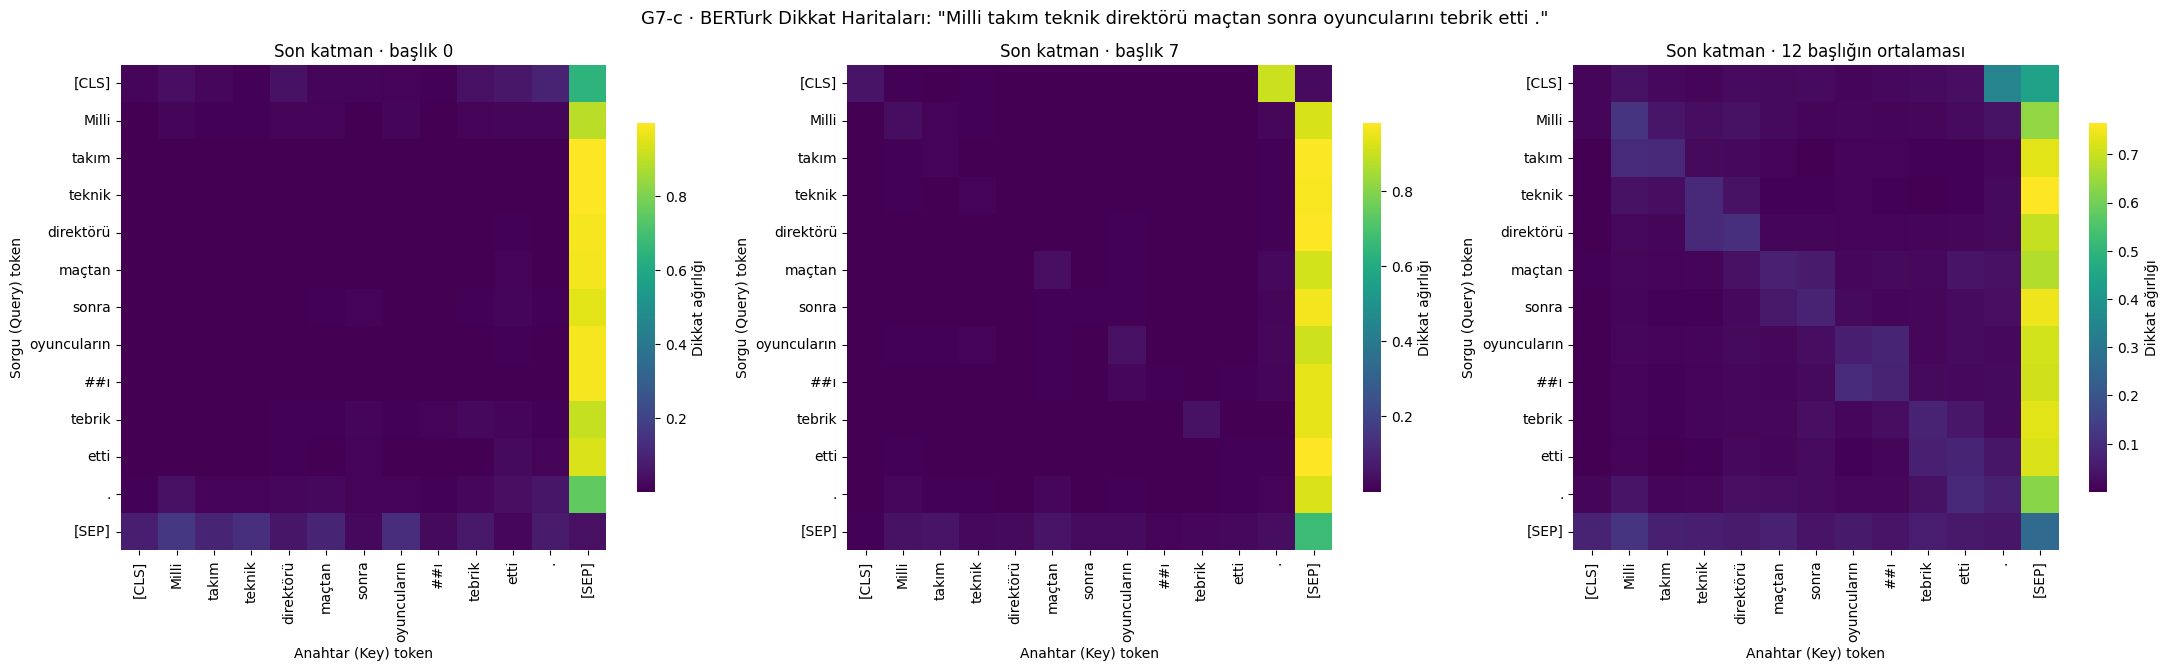

Son katman · başlık 0: [SEP]'e ort. dikkat = 0.94 | en güçlü bağlar: [('.', 'Milli', 0.04), ('.', 'etti', 0.04), ('.', 'maçtan', 0.02), ('.', 'direktörü', 0.02), ('.', 'tebrik', 0.02)]
Son katman · başlık 7: [SEP]'e ort. dikkat = 0.95 | en güçlü bağlar: [('maçtan', '.', 0.02), ('.', 'Milli', 0.02), ('oyuncuların', '.', 0.02), ('.', 'maçtan', 0.02), ('##ı', 'oyuncuların', 0.02)]
Son katman · 12 başlığın ortalaması: [SEP]'e ort. dikkat = 0.70 | en güçlü bağlar: [('##ı', 'oyuncuların', 0.09), ('takım', 'Milli', 0.09), ('.', 'etti', 0.09), ('direktörü', 'teknik', 0.09), ('oyuncuların', '##ı', 0.08)]


In [35]:
# ------------------------------------------------------------------
# G7-c | Bu hücrede model output_attentions=True ile çalıştırılarak bir cümlenin
# dikkat ağırlıkları alınır; katman/başlık sayısı yazdırılır. Son katmandan iki
# başlığın ve tüm başlıkların ortalamasının dikkat haritası, token etiketli ısı
# haritaları olarak yan yana çizilir.
# ------------------------------------------------------------------
DIKKAT_CUMLESI = "Milli takım teknik direktörü maçtan sonra oyuncularını tebrik etti ."
kod = tokenizer(DIKKAT_CUMLESI, return_tensors="pt")
with torch.no_grad():
    dikkatler = bert(**kod).attentions             # katman sayısı kadar (1, başlık, n, n) tensör
tokenlar = tokenizer.convert_ids_to_tokens(kod["input_ids"][0])

KATMAN_SAYISI = len(dikkatler)
BASLIK_SAYISI = dikkatler[-1].shape[1]
print(f"Katman sayısı: {KATMAN_SAYISI} | Başlık (head) sayısı: {BASLIK_SAYISI} | Token sayısı: {len(tokenlar)}")
print("Tokenlar:", tokenlar)

son_katman = dikkatler[-1][0].numpy()              # (başlık, n, n)
BASLIK_1, BASLIK_2 = 0, 7                          # karşılaştırılacak iki başlık
haritalar = {f"Son katman · başlık {BASLIK_1}": son_katman[BASLIK_1],
             f"Son katman · başlık {BASLIK_2}": son_katman[BASLIK_2],
             f"Son katman · {BASLIK_SAYISI} başlığın ortalaması": son_katman.mean(axis=0)}

fig, axes = plt.subplots(1, 3, figsize=(22, 6.5))
for ax, (baslik, matris) in zip(axes, haritalar.items()):
    sns.heatmap(matris, xticklabels=tokenlar, yticklabels=tokenlar, cmap="viridis", ax=ax,
                square=True, cbar_kws={"label": "Dikkat ağırlığı", "shrink": 0.7})
    ax.set_title(baslik); ax.set_xlabel("Anahtar (Key) token"); ax.set_ylabel("Sorgu (Query) token")
    ax.tick_params(axis="x", rotation=90)
plt.suptitle(f"G7-c · BERTurk Dikkat Haritaları: \"{DIKKAT_CUMLESI}\"", fontsize=13)
plt.tight_layout(); plt.show()

# Yorum için: her haritada [CLS]/[SEP]/kendisi dışındaki en güçlü 5 dikkat bağlantısı
ozel = {tokenizer.cls_token, tokenizer.sep_token}
for baslik, matris in haritalar.items():
    ciftler = [(tokenlar[i], tokenlar[j], matris[i, j]) for i in range(len(tokenlar)) for j in range(len(tokenlar))
               if i != j and tokenlar[i] not in ozel and tokenlar[j] not in ozel]
    ciftler = sorted(ciftler, key=lambda x: -x[2])[:5]
    sep_payi = matris[1:-1, -1].mean()              # gerçek tokenların [SEP]'e verdiği ortalama dikkat
    print(f"{baslik}: [SEP]'e ort. dikkat = {sep_payi:.2f} | en güçlü bağlar:",
          [(a, b, round(float(s), 2)) for a, b, s in ciftler])

In [36]:
# ------------------------------------------------------------------
# G7-d (1/2) | Bu hücrede sınıf oranları korunarak 1.000 kayıtlık alt küme alınır
# ve her metin için BERTurk mean pooling temsili (768 boyut) çıkarılır.
# Metinler max_length=128 ile kesilir; işlem torch.no_grad() altında 32'lik
# gruplar hâlinde yapılır. Mean pooling'de dolgu (padding) tokenları attention_mask
# ile dışarıda bırakılır.
# ------------------------------------------------------------------
alt_kume, _ = train_test_split(df, train_size=1000, stratify=df["kategori"], random_state=SEED)
alt_kume = alt_kume.reset_index(drop=True)
print("Alt küme sınıf dağılımı:", alt_kume["kategori"].value_counts().to_dict())

def bert_temsil(metinler, grup=32, max_uzunluk=128):
    temsiller = []
    for bas in range(0, len(metinler), grup):
        kod = tokenizer(metinler[bas:bas + grup], padding=True, truncation=True,
                        max_length=max_uzunluk, return_tensors="pt")
        with torch.no_grad():                                         # gradyan yok, ince ayar yok
            h = bert(**kod).last_hidden_state                         # (grup, n, 768)
        maske = kod["attention_mask"].unsqueeze(-1).float()            # (grup, n, 1)
        ortalama = (h * maske).sum(dim=1) / maske.sum(dim=1)           # mean pooling
        temsiller.append(ortalama.numpy())
    return np.vstack(temsiller)

# BERT girdisi: ham metnin yalnızca ilk 150 kelimesi (128 token sınırını zaten aşar) ve özel adlar düzeltilmiş
bert_metinleri = [bert_icin_hazirla(" ".join(m.split()[:150])) for m in alt_kume["metin"]]
t0 = time.time()
X_bert = bert_temsil(bert_metinleri)
print(f"BERTurk temsil matrisi: {X_bert.shape} | süre: {time.time() - t0:.1f} sn")

Alt küme sınıf dağılımı: {'siyaset': 152, 'ekonomi': 152, 'dunya': 149, 'teknoloji': 143, 'spor': 140, 'saglik': 139, 'kultur': 125}
BERTurk temsil matrisi: (1000, 768) | süre: 598.9 sn


,Yaklaşım,Accuracy,F1 (macro)
0,TF-IDF + Doğrusal SVM,0.845,0.8457
1,BERTurk (mean pooling) + Lojistik Regresyon,0.880,0.8815


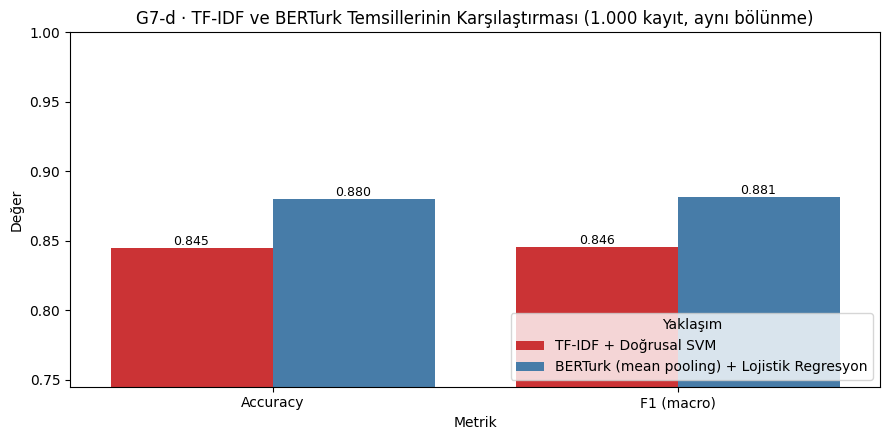

Otomatik özet: BERTurk temsili macro-F1'de TF-IDF'e göre +0.0358 fark gösteriyor (BERTurk daha iyi).

BERTurk + LR sınıflandırma raporu:
              precision    recall  f1-score   support

       dunya      0.867     0.867     0.867        30
     ekonomi      0.857     0.800     0.828        30
      kultur      0.880     0.880     0.880        25
      saglik      0.929     0.929     0.929        28
     siyaset      0.871     0.900     0.885        30
        spor      1.000     0.929     0.963        28
   teknoloji      0.781     0.862     0.820        29

    accuracy                          0.880       200
   macro avg      0.884     0.881     0.882       200
weighted avg      0.882     0.880     0.881       200



In [37]:
# ------------------------------------------------------------------
# G7-d (2/2) | Bu hücrede BERTurk temsilleriyle Lojistik Regresyon eğitilir
# (%80/%20, stratify, random_state=42). Aynı alt küme ve AYNI bölünme üzerinde
# G6'daki en iyi TF-IDF modeli de (vektörleştirici yalnızca eğitimde fit) çalıştırılır.
# İki yaklaşımın accuracy ve macro-F1 değerleri tablo ve grafikle karşılaştırılır.
# ------------------------------------------------------------------
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

idx_tr, idx_te = train_test_split(np.arange(len(alt_kume)), test_size=0.20,
                                  stratify=alt_kume["kategori"], random_state=SEED)
y_alt = alt_kume["kategori"].values

# (1) BERTurk + Lojistik Regresyon (özellikler ölçeklenir; ölçekleyici yalnızca eğitimde fit)
bert_lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.1, random_state=SEED))
bert_lr.fit(X_bert[idx_tr], y_alt[idx_tr])
tahmin_bert = bert_lr.predict(X_bert[idx_te])

# (2) G6'daki en iyi TF-IDF modeli, aynı alt küme ve aynı bölünmeyle
en_iyi_tfidf = sonuc_tablosu[sonuc_tablosu["Temsil"] == "TF-IDF"].iloc[0]
tfidf_alt = TfidfVectorizer(min_df=2, sublinear_tf=True)
Xtr_alt = tfidf_alt.fit_transform(alt_kume["islenmis"].values[idx_tr])
Xte_alt = tfidf_alt.transform(alt_kume["islenmis"].values[idx_te])
tfidf_model = clone(modeller[en_iyi_tfidf["Model"]]).fit(Xtr_alt, y_alt[idx_tr])
tahmin_tfidf = tfidf_model.predict(Xte_alt)

karsilastirma_g7 = pd.DataFrame([
    {"Yaklaşım": f"TF-IDF + {en_iyi_tfidf['Model']}", "Accuracy": accuracy_score(y_alt[idx_te], tahmin_tfidf),
     "F1 (macro)": f1_score(y_alt[idx_te], tahmin_tfidf, average="macro")},
    {"Yaklaşım": "BERTurk (mean pooling) + Lojistik Regresyon", "Accuracy": accuracy_score(y_alt[idx_te], tahmin_bert),
     "F1 (macro)": f1_score(y_alt[idx_te], tahmin_bert, average="macro")}]).round(4)
display(karsilastirma_g7)

uzun = karsilastirma_g7.melt(id_vars="Yaklaşım", var_name="Metrik", value_name="Değer")
plt.figure(figsize=(9, 4.5))
ax = sns.barplot(data=uzun, x="Metrik", y="Değer", hue="Yaklaşım", palette="Set1")
for kap in ax.containers:
    ax.bar_label(kap, fmt="%.3f", fontsize=9)
ax.set_ylim(max(0, uzun["Değer"].min() - 0.1), 1.0)
ax.set_title("G7-d · TF-IDF ve BERTurk Temsillerinin Karşılaştırması (1.000 kayıt, aynı bölünme)")
ax.set_xlabel("Metrik"); ax.set_ylabel("Değer"); ax.legend(title="Yaklaşım", loc="lower right")
plt.tight_layout(); plt.show()

fark = karsilastirma_g7.loc[1, "F1 (macro)"] - karsilastirma_g7.loc[0, "F1 (macro)"]
print(f"Otomatik özet: BERTurk temsili macro-F1'de TF-IDF'e göre {fark:+.4f} fark gösteriyor "
      f"({'BERTurk daha iyi' if fark > 0 else 'TF-IDF daha iyi ya da eşit'}).")
print("\nBERTurk + LR sınıflandırma raporu:")
print(classification_report(y_alt[idx_te], tahmin_bert, digits=3))

## G7 · Değerlendirme
- **Tokenization (G7-a):** BERTurk'ün sözlüğü 32.000 WordPiece biriminden oluşmaktadır. Her dizinin başına sınıflandırma ve cümle temsili için `[CLS]` (ID 2), sonuna cümle sınırını belirten `[SEP]` (ID 3) eklenmektedir. Tek cümlede dolgu (padding) olmadığı için `attention_mask` tamamen 1'dir; gruplar hâlinde işlemede dolgu tokenları 0 alarak dikkat hesabının dışında kalmaktadır. `##` ile başlayan parçalar bir kelimenin devamını göstermektedir. Örneğin `gözlükçülerimizden` kelimesi `gözlük + ##çü + ##lerimizden` olarak bölünmüştür: sık kökler tek token kalırken ekler ayrı parçalara ayrılmakta, böylece sözlükte olmayan kelimeler (OOV) de temsil edilebilmektedir. Bu bölünme nedeniyle BERTurk token sayısı G2'deki kelime sayısından **1,16–1,60 kat** fazla çıkmıştır. Dikkat çekici bir bulgu da modelin büyük/küçük harf duyarlı olmasının etkisidir: küçük harfle yazılmış `fransa` (`fran + ##sa`), `pkk` (`p + ##kk`) ve `rusya` (`rus + ##ya`) gibi özel adlar parçalanmıştır; bu kelimeler büyük harfle yazılsaydı sözlükte tek token olarak bulunurlardı.
- **Bağlamsal temsil (G7-b):** `last_hidden_state` boyutu `(1, 15, 768)` olarak bulunmuştur: grup boyutu, `[CLS]`/`[SEP]` dahil token sayısı ve gizli katman boyutu. "yüz" kelimesi dört cümlede de tek token olmasına rağmen vektörleri bağlama göre değişmiştir. Aynı anlamdaki kullanımlar (surat: A–B) arasındaki kosinüs benzerliği **0,880** iken, farklı anlamdaki kullanımlarla benzerlik daha düşüktür: sayı anlamıyla (A–C) 0,657, yüzmek fiiliyle (A–D) 0,418. Word2Vec ise her kelime türü için tek bir statik vektör tuttuğundan "yüz" kelimesinin tüm anlamları aynı vektörde karışmaktadır. Bu durum Word2Vec'te "yüz"e en yakın kelimelerin (`felçli`, `kordon`, `ömrünün`, `ışığı`, `derslik`) ortak bir anlam alanı oluşturmamasında da açıkça görülmektedir.
- **Dikkat (G7-c):** BERTurk'ün 12 katman ve katman başına 12 dikkat başlığından oluştuğu görülmüştür. Son katmandaki 0. ve 7. başlıklarda gerçek tokenların dikkatinin **%94–95'i `[SEP]` tokenına** gitmektedir; kelimeler arasındaki en güçlü bağlar 0,02–0,04 düzeyinde kalmaktadır. Bu, BERT'te bilinen "boşta bekleme" (no-op) davranışıdır: bu başlıklar bu cümle için anlamlı bir ilişki taşımamaktadır. 12 başlığın ortalamasında ise `[SEP]` payı 0,70'e inmekte ve dilbilgisel olarak anlamlı bağlar ortaya çıkmaktadır: alt kelime birleştirme (`oyuncuların` ↔ `##ı`) ve tamlama ilişkileri (`takım → Milli`, `direktörü → teknik`, her biri 0,09). Bu sonuç, bilginin tek başlıkta değil başlıklara dağılmış olarak tutulduğunu göstermektedir. **Multi-head attention**'ın amacı da tam olarak budur: farklı alt uzaylarda farklı ilişki türlerinin (konum, alt kelime, sözdizimi) paralel olarak öğrenilmesi.
- **Sınıflandırma (G7-d):** Aynı 1.000 kayıtlık alt küme ve aynı %80/%20 bölünme üzerinde, ince ayar yapılmadan çıkarılan BERTurk temsilleri **daha başarılı** bulunmuştur: BERTurk + Lojistik Regresyon için accuracy 0,880 ve macro-F1 0,882, TF-IDF + Doğrusal SVM için 0,845 ve 0,846 (fark +0,036). TF-IDF modelinin başarısı tüm veride 0,914 iken eğitim örneği 800'e düşünce 0,846'ya gerilemiştir. Seyrek ve kelimeye dayalı temsil az veriyle iyi genelleme yapamamakta, önceden eğitilmiş BERTurk ise eş anlamlıları ve bağlamı büyük derlemlerden öğrendiği için az örnekle de güçlü kalmaktadır. Bu üstünlük şu dezavantajlara rağmen elde edilmiştir:
  - BERTurk yalnızca ilk 128 tokenı görmüştür.
  - Veri, modelin eğitildiği metinlerden farklı olarak küçük harfli ve noktalamasızdır.
  - Model ince ayar görmemiştir.

  Bunun bedeli hesaplama maliyetidir: 1.000 metnin temsilini çıkarmak CPU'da yaklaşık **599 saniye (10 dakika)** sürmüş ve defterin toplam süresinin yarısından fazlasını oluşturmuştur; TF-IDF modeli ise saniyeler içinde eğitilmiştir. Test kümesinin yalnızca 200 örnek olduğu ve tek bir bölünme kullanıldığı göz önüne alındığında 3,6 puanlık fark bir eğilim olarak yorumlanmalıdır.

In [38]:
# ------------------------------------------------------------------
# SÜRE KONTROLÜ | Bu hücrede defterin toplam çalışma süresi yazdırılır
# (yönerge sınırı: Colab CPU'da 20 dakika).
# ------------------------------------------------------------------
toplam = time.time() - BASLANGIC_ZAMANI
print(f"Toplam çalışma süresi: {toplam / 60:.1f} dakika")

Toplam çalışma süresi: 18.7 dakika


---
## **Genel Sonuç**
---
Bu çalışmada TTC4900 haber veri seti üzerinde uçtan uca bir Türkçe NLP hattı kurulmuştur. Veri setinin küçük harfli, noktalamasız ve kesme işaretiyle ayrılan eklerinin kopuk olması, ön işlemenin veriye göre uyarlanmasını gerektirmiştir: Türkçe küçük harf dönüşümü, kopuk ek stop-word'leri, yüklem tabanlı sözde cümle bölme ve özel adlara büyük harfin geri kazandırılması bu nedenle eklenmiştir. Bu özelliklerin POS etiketleme, bağımlılık çözümlemesi ve NER başarısını belirgin biçimde düşürdüğü gözlenmiştir. Tüm veri kullanıldığında **TF-IDF + Doğrusal SVM** 0,914 macro-F1 ile en iyi klasik model olmuştur. 1.000 kayıtlık alt kümede ise ince ayar yapılmamış **BERTurk** temsilleri 0,882 macro-F1 ile aynı model türünü (0,846) geride bırakmıştır; bu sonuç, önceden eğitilmiş bağlamsal temsillerin az veriyle çalışırken sağladığı avantajı göstermektedir. Defterin tamamı Colab CPU'da 18,7 dakikada çalışmıştır.